# Decoder-Only Transformer from Scratch (NumPy)

**Track 3 - GPT Report.** This notebook implements an autoregressive, decoder-only
Transformer language model entirely in NumPy, including a manually derived backward
pass. No autograd framework is used at any point. Every layer implements `forward`
and `backward` explicitly, and a component only counts as done once its backward
pass has passed an isolated numerical gradient check.

The assignment asks for a classical decoder-only Transformer, so that is what was
built first: a GPT-2-style baseline with learned positional embeddings, LayerNorm,
and a ReLU feedforward block, trained and evaluated end to end. Only after that
baseline worked and every gradient check passed was the architecture extended, one
component at a time, toward a design closer to the LLaMA and Mistral family:

- **RMSNorm** in place of LayerNorm (Pre-Norm placement)
- **SwiGLU** in place of the ReLU feedforward
- **RoPE** (Rotary Position Embeddings) in place of additive positional embeddings
- **Weight tying** between the token embedding and the output projection

The baseline is not discarded by any of these steps. Every classic component
remains a live code path, selected by a `use_*` flag on the config object, which
is what lets Phase 6 compare all five variants without duplicating the model class.

The notebook is organized by development phase:

0. Foundation: config, tokenizer, data pipeline
1. Baseline forward pass (classic components)
2. Baseline backward pass and gradient checking
3. Training loop (AdamW from scratch)
4. Text generation (greedy / temperature / top-k / top-p)
5. Modernization: swap in RMSNorm, SwiGLU, RoPE, weight tying one at a time
6. Analysis: ablation comparison and hyperparameter study


## How to Run This Notebook

The project grew well past a single training run. Because each modernization step
was introduced separately and kept its own model, its own gradient check, and its
own training run, Phase 5 alone produces five independent 2000-step runs, and
Phase 6 adds eight more for the hyperparameter sweep. On CPU each of the five main
runs takes roughly 85 minutes, so a full "Run All" from scratch is on the order of
7 to 8 hours.

That is impractical for anyone reading or grading this notebook, so every training
run is cached to disk:

- `runs/` holds the five ablation runs from Phases 3 and 5
- `hp_runs/` holds the eight hyperparameter-sweep runs from Phase 6

Both folders ship with the submission. With them in place a full "Run All"
completes in a few minutes: each training cell detects its cached result, loads the
recorded history and checkpoints, and skips the computation. Everything else still
executes normally, including every gradient check and the single-batch overfitting
test, so the notebook still verifies itself end to end on a fresh kernel.

To reproduce the training from scratch instead, set `RETRAIN = True` in the cell
below, or delete the two folders. The cells will then train and write fresh caches
as they go.


In [1]:
# Set to True to force full retraining of all 5 ablation runs, ignoring any
# cached results in runs/. Set to False (default) to load cached results
# when available, which is what makes a full "Run All" take minutes instead
# of ~7-8 hours.
RETRAIN = False

In [2]:
import os
import math
import time
import urllib.request
from dataclasses import dataclass, field

import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)


def set_seed(seed: int) -> None:
    """Seed NumPy's global RNG for reproducible batches, init, and sampling."""
    np.random.seed(seed)


SEED = 1337
set_seed(SEED)
DTYPE = np.float32  # consistent float dtype across the whole pipeline

## 0.1 Configuration

A single config object holds every model and training hyperparameter. The `use_*`
flags let the exact same training/eval code run either the classic baseline
components or the modern replacements, which is what makes the Phase 5 ablation
possible without duplicating code.

In [3]:
@dataclass
class GPTConfig:
    # Data / vocab
    vocab_size: int = 0          # set after tokenizer is built
    context_length: int = 128    # T

    # Model size
    n_layers: int = 4
    n_heads: int = 4
    d_model: int = 128
    d_ff: int = 4 * 128          # overridden below for SwiGLU sizing if needed

    # Regularization
    dropout: float = 0.0

    # Architecture switches (baseline=False -> modern=True during Phase 5)
    use_rmsnorm: bool = False
    use_swiglu: bool = False
    use_rope: bool = False
    use_weight_tying: bool = False

    # Training
    batch_size: int = 32
    learning_rate: float = 3e-4
    weight_decay: float = 0.1
    warmup_steps: int = 100
    max_steps: int = 2000
    grad_clip_norm: float = 1.0

    def __post_init__(self):
        assert self.d_model % self.n_heads == 0, "d_model must be divisible by n_heads"


config = GPTConfig()
config

GPTConfig(vocab_size=0, context_length=128, n_layers=4, n_heads=4, d_model=128, d_ff=512, dropout=0.0, use_rmsnorm=False, use_swiglu=False, use_rope=False, use_weight_tying=False, batch_size=32, learning_rate=0.0003, weight_decay=0.1, warmup_steps=100, max_steps=2000, grad_clip_norm=1.0)

## 0.2 Dataset: Tiny Shakespeare

We use the Tiny Shakespeare corpus (~1.1M characters), the standard small-scale
reference dataset for from-scratch character-level language models. It is small
enough to train quickly in pure NumPy while still containing enough structure
(dialogue, verse, punctuation) to make training progress and generation quality
visible.


In [4]:
DATA_PATH = "input.txt"
DATA_URL = (
    "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
)

if not os.path.exists(DATA_PATH):
    urllib.request.urlretrieve(DATA_URL, DATA_PATH)

with open(DATA_PATH, "r", encoding="utf-8") as f:
    text = f.read()

print(f"corpus length: {len(text):,} characters")
print(text[:300])

corpus length: 1,115,394 characters
First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us


## 0.3 Tokenizer: Character-Level

Per the assignment, Track 3 does not require a hand-built tokenizer, and a simple
char-level tokenizer is explicitly permitted. We build the vocabulary from the set
of unique characters in the corpus and map each to an integer id.


In [5]:
class CharTokenizer:
    """Minimal character-level tokenizer: one integer id per unique character."""

    def __init__(self, text: str):
        chars = sorted(set(text))
        self.vocab_size = len(chars)
        self.stoi = {ch: i for i, ch in enumerate(chars)}
        self.itos = {i: ch for i, ch in enumerate(chars)}

    def encode(self, s: str) -> np.ndarray:
        return np.array([self.stoi[c] for c in s], dtype=np.int64)

    def decode(self, ids) -> str:
        return "".join(self.itos[int(i)] for i in ids)


tokenizer = CharTokenizer(text)
config.vocab_size = tokenizer.vocab_size
print(f"vocab size: {tokenizer.vocab_size}")
print("".join(tokenizer.itos[i] for i in range(tokenizer.vocab_size)))

vocab size: 65

 !$&',-.3:;?ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz


## 0.4 Data Pipeline: Batching and Train/Val Split

The full corpus is encoded once into a single array of token ids. We hold out a
validation slice at the end of the stream and sample random context windows from
train/val separately. Targets are the input sequence shifted by one position, which
is what turns this into a next-token prediction task.


In [6]:
data = tokenizer.encode(text)

split_idx = int(0.9 * len(data))
train_data = data[:split_idx]
val_data = data[split_idx:]

print(f"train tokens: {len(train_data):,} | val tokens: {len(val_data):,}")


def get_batch(split: str, config: GPTConfig, batch_size: int = None):
    """Sample a random batch of (input, target) sequences.

    Returns x, y of shape (batch_size, context_length), where y[i] is x[i]
    shifted one position to the right (next-token targets).
    """
    d = train_data if split == "train" else val_data
    bs = batch_size or config.batch_size
    T = config.context_length

    # random start offsets, leaving room for one extra token (the final target)
    ix = np.random.randint(0, len(d) - T - 1, size=bs)
    x = np.stack([d[i : i + T] for i in ix]).astype(np.int64)
    y = np.stack([d[i + 1 : i + T + 1] for i in ix]).astype(np.int64)
    return x, y

train tokens: 1,003,854 | val tokens: 111,540


## 0.5 Sanity Check

Phase 0 is done once we can pull a batch of the correct shape and decode it back
into readable text, confirming the tokenizer, split, and batching logic all agree
with each other.

In [7]:
xb, yb = get_batch("train", config)
print("x shape:", xb.shape, "| y shape:", yb.shape)

print("\n--- decoded input[0] ---")
print(tokenizer.decode(xb[0]))

print("\n--- decoded target[0] (shifted by 1) ---")
print(tokenizer.decode(yb[0]))

# targets should equal inputs shifted left by one position
assert np.array_equal(xb[0][1:], yb[0][:-1]), "shift-by-one relationship broken"
print("\nOK: target is input shifted by one token.")

x shape: (32, 128) | y shape: (32, 128)

--- decoded input[0] ---
I:
Why, Buckingham, I say, I would be king,

BUCKINGHAM:
Why, so you are, my thrice renowned liege.

KING RICHARD III:
Ha! am I 

--- decoded target[0] (shifted by 1) ---
:
Why, Buckingham, I say, I would be king,

BUCKINGHAM:
Why, so you are, my thrice renowned liege.

KING RICHARD III:
Ha! am I k

OK: target is input shifted by one token.


## 1.0 Layer Interface

Every component in this project follows the same contract: `forward(x, ...)`
computes the output and stashes everything the backward pass will need in
`self.cache`; `backward(dout)` (added in Phase 2) uses that cache to compute
gradients w.r.t. the input and accumulate parameter gradients in `self.grads`.
There is no autograd tape. The caller chains layers explicitly and calls
`backward` in reverse order, which keeps the chain rule visible in the code.


In [8]:
class Layer:
    """Base contract every component implements.

    forward(x, ...) -> out   stores everything backward() will need in self.cache
    backward(dout)  -> dx    accumulates parameter gradients into self.grads

    Phase 1 only implements forward(); backward() is filled in during Phase 2,
    one component at a time, each verified with a numerical gradient check.
    """

    def __init__(self):
        self.cache = {}
        self.params = {}
        self.grads = {}

    def forward(self, *args, **kwargs):
        raise NotImplementedError

    def backward(self, dout):
        raise NotImplementedError("Backward pass built in Phase 2")

    def zero_grad(self):
        for k in self.grads:
            self.grads[k] = np.zeros_like(self.params[k])

## 1.1 Token Embedding and Positional Embedding (baseline: learned)

The baseline uses a learned positional embedding table added to the token
embeddings, following the original GPT-2 design. This will be replaced by RoPE
in Phase 5.

In [9]:
class Embedding(Layer):
    """Token embedding lookup table, shape (vocab_size, d_model)."""

    def __init__(self, vocab_size, d_model):
        super().__init__()
        self.params['weight'] = (np.random.randn(vocab_size, d_model) * 0.02).astype(DTYPE)
        self.grads['weight'] = np.zeros_like(self.params['weight'])

    def forward(self, ids):
        self.cache['ids'] = ids
        return self.params['weight'][ids]  # (B, T, d_model)

    def backward(self, dout):
        """Scatter-add dout into the rows that were looked up.

        np.add.at (not a plain indexed assignment) is required because the
        same token id can appear more than once in a batch, those
        contributions must accumulate, not overwrite each other.
        """
        ids = self.cache['ids']
        np.add.at(self.grads['weight'], ids, dout)
        return None  # ids are integers, not differentiable


class LearnedPositionalEmbedding(Layer):
    """Learned positional embedding table, shape (context_length, d_model)."""

    def __init__(self, context_length, d_model):
        super().__init__()
        self.params['weight'] = (np.random.randn(context_length, d_model) * 0.02).astype(DTYPE)
        self.grads['weight'] = np.zeros_like(self.params['weight'])

    def forward(self, T):
        self.cache['T'] = T
        return self.params['weight'][:T]  # (T, d_model), broadcast over batch by the caller

    def backward(self, dout):
        """dout has shape (T, d_model): the batch-summed gradient.

        This layer's output is broadcast (shared, not repeated) across the
        batch dimension by the caller (`x = tok + pos[None,:,:]`), so the
        caller is responsible for summing the incoming gradient over the
        batch axis *before* calling this, this layer just scatters the
        already-summed gradient into the first T rows of its weight table.
        """
        T = self.cache['T']
        self.grads['weight'][:T] += dout


## 1.2 LayerNorm

Baseline normalization layer (Pre-Norm placement inside each block). This will
be replaced by RMSNorm in Phase 5.

In [10]:
class LayerNorm(Layer):
    def __init__(self, d_model, eps=1e-5):
        super().__init__()
        self.eps = eps
        self.params['gamma'] = np.ones(d_model, dtype=DTYPE)
        self.params['beta'] = np.zeros(d_model, dtype=DTYPE)
        self.grads['gamma'] = np.zeros_like(self.params['gamma'])
        self.grads['beta'] = np.zeros_like(self.params['beta'])

    def forward(self, x):
        mu = x.mean(axis=-1, keepdims=True)
        var = x.var(axis=-1, keepdims=True)
        x_hat = (x - mu) / np.sqrt(var + self.eps)
        out = self.params['gamma'] * x_hat + self.params['beta']
        self.cache.update(dict(x_hat=x_hat, var=var))
        return out

    def backward(self, dout):
        """Backward pass for y = gamma * x_hat + beta, x_hat = (x-mu)/sqrt(var+eps).

        gamma/beta gradients are simple sums since they broadcast over every
        leading (batch, time) position:
            dgamma = sum(dout * x_hat)   over all leading dims
            dbeta  = sum(dout)           over all leading dims

        dx is the standard normalization-layer backward: because mu and var are
        themselves functions of every element of x, dx has three terms, the
        direct term, a term correcting for how perturbing x shifts the mean,
        and a term correcting for how it shifts the variance:

            dx = (1/D) * inv_std * ( D*dxhat - sum(dxhat) - x_hat*sum(dxhat*x_hat) )

        where D is the size of the normalized (last) axis and dxhat = dout*gamma.
        """
        x_hat = self.cache['x_hat']
        var = self.cache['var']
        D = x_hat.shape[-1]
        inv_std = 1.0 / np.sqrt(var + self.eps)

        reduce_axes = tuple(range(dout.ndim - 1))  # sum over batch & time, keep feature dim
        self.grads['gamma'] += np.sum(dout * x_hat, axis=reduce_axes)
        self.grads['beta'] += np.sum(dout, axis=reduce_axes)

        dx_hat = dout * self.params['gamma']
        sum_dxhat = np.sum(dx_hat, axis=-1, keepdims=True)
        sum_dxhat_xhat = np.sum(dx_hat * x_hat, axis=-1, keepdims=True)

        dx = (inv_std / D) * (D * dx_hat - sum_dxhat - x_hat * sum_dxhat_xhat)
        return dx


## 1.3 Causal Multi-Head Self-Attention

Standard scaled dot-product attention with a causal mask: position *t* may only
attend to positions ≤ *t*. The mask is applied additively (large negative value)
**before** the softmax, not multiplicatively after, for numerical correctness.
Softmax uses max-subtraction for stability.

In [11]:
# Extended in Phase 5 to take a use_rope flag. With use_rope=False this is
# the plain baseline attention from Phase 1; the RoPE path is opt-in, so the
# original behaviour is preserved rather than replaced.
class CausalSelfAttention(Layer):
    def __init__(self, d_model, n_heads, use_rope=False, context_length=None):
        super().__init__()
        assert d_model % n_heads == 0
        self.n_heads = n_heads
        self.d_head = d_model // n_heads
        self.d_model = d_model
        self.use_rope = use_rope

        scale = 1.0 / math.sqrt(d_model)
        for name in ['Wq', 'Wk', 'Wv', 'Wo']:
            self.params[name] = (np.random.randn(d_model, d_model) * scale).astype(DTYPE)
            self.grads[name] = np.zeros_like(self.params[name])

        if use_rope:
            assert context_length is not None, "RoPE needs context_length to build its angle table"
            self.rope_q = RoPE(self.d_head, context_length)
            self.rope_k = RoPE(self.d_head, context_length)
            self.sublayers = [self.rope_q, self.rope_k]
        else:
            self.sublayers = []

    def _split_heads(self, x):
        B, T, D = x.shape
        x = x.reshape(B, T, self.n_heads, self.d_head)
        return x.transpose(0, 2, 1, 3)  # (B, H, T, d_head)

    def _merge_heads(self, x):
        B, H, T, dh = x.shape
        x = x.transpose(0, 2, 1, 3)
        return x.reshape(B, T, H * dh)

    def forward(self, x):
        B, T, D = x.shape
        q = self._split_heads(x @ self.params['Wq'])
        k = self._split_heads(x @ self.params['Wk'])
        v = self._split_heads(x @ self.params['Wv'])

        if self.use_rope:
            q = self.rope_q.forward(q)
            k = self.rope_k.forward(k)
        # from here on, q and k are the ROTATED tensors -- these are what the
        # score computation uses, so these are what the backward pass needs

        scores = q @ k.transpose(0, 1, 3, 2) / math.sqrt(self.d_head)  # (B,H,T,T)

        causal_mask = np.triu(np.ones((T, T), dtype=bool), k=1)
        scores = np.where(causal_mask, np.float32(-1e9), scores)

        scores_max = scores.max(axis=-1, keepdims=True)
        exp_scores = np.exp(scores - scores_max)
        attn = exp_scores / exp_scores.sum(axis=-1, keepdims=True)

        merged = self._merge_heads(attn @ v)
        out = merged @ self.params['Wo']

        self.cache.update(dict(x=x, q=q, k=k, v=v, attn=attn, merged=merged))
        return out

    def backward(self, dout):
        """See the Phase 2 derivation; the only addition is the RoPE inverse
        rotation applied to dq/dk before they reach Wq/Wk."""
        x, q, k, v, attn, merged = (
            self.cache[key] for key in ['x', 'q', 'k', 'v', 'attn', 'merged']
        )

        self.grads['Wo'] += np.einsum('btd,bte->de', merged, dout)
        dmerged = dout @ self.params['Wo'].T
        dout_heads = self._split_heads(dmerged)

        dattn = dout_heads @ v.transpose(0, 1, 3, 2)
        dv = np.einsum('bhqk,bhqd->bhkd', attn, dout_heads)

        dscores = attn * (dattn - np.sum(attn * dattn, axis=-1, keepdims=True))

        scale = 1.0 / math.sqrt(self.d_head)
        dq = (dscores @ k) * scale                              # w.r.t. rotated q
        dk = np.einsum('bhqk,bhqd->bhkd', dscores, q) * scale    # w.r.t. rotated k

        if self.use_rope:
            dq = self.rope_q.backward(dq)   # inverse rotation
            dk = self.rope_k.backward(dk)

        dq_m = self._merge_heads(dq)
        dk_m = self._merge_heads(dk)
        dv_m = self._merge_heads(dv)

        self.grads['Wq'] += np.einsum('btd,bte->de', x, dq_m)
        self.grads['Wk'] += np.einsum('btd,bte->de', x, dk_m)
        self.grads['Wv'] += np.einsum('btd,bte->de', x, dv_m)

        dx = dq_m @ self.params['Wq'].T + dk_m @ self.params['Wk'].T + dv_m @ self.params['Wv'].T
        return dx


## 1.4 Feedforward (baseline: ReLU)

Standard two-layer MLP with ReLU. This will be replaced by SwiGLU in Phase 5.

In [12]:
class ReLUFeedForward(Layer):
    def __init__(self, d_model, d_ff):
        super().__init__()
        s1, s2 = 1.0 / math.sqrt(d_model), 1.0 / math.sqrt(d_ff)
        self.params['W1'] = (np.random.randn(d_model, d_ff) * s1).astype(DTYPE)
        self.params['b1'] = np.zeros(d_ff, dtype=DTYPE)
        self.params['W2'] = (np.random.randn(d_ff, d_model) * s2).astype(DTYPE)
        self.params['b2'] = np.zeros(d_model, dtype=DTYPE)
        for name in ['W1', 'b1', 'W2', 'b2']:
            self.grads[name] = np.zeros_like(self.params[name])

    def forward(self, x):
        z = x @ self.params['W1'] + self.params['b1']
        a = np.maximum(z, 0)
        out = a @ self.params['W2'] + self.params['b2']
        self.cache.update(dict(x=x, z=z, a=a))
        return out

    def backward(self, dout):
        """Backward for out = relu(x@W1 + b1) @ W2 + b2.

        Two affine maps with a ReLU gate in between: the gate passes gradient
        through unchanged where z>0 and blocks it (derivative 0) where z<=0.
        Parameter gradients sum contributions over every (batch, time)
        position, since the same weights are applied independently at each
        position, this is why we use einsum with 'bt...' contracted away
        rather than a plain matmul.
        """
        x, z, a = self.cache['x'], self.cache['z'], self.cache['a']

        self.grads['W2'] += np.einsum('btf,btd->fd', a, dout)
        self.grads['b2'] += dout.sum(axis=(0, 1))

        da = dout @ self.params['W2'].T
        dz = da * (z > 0)  # ReLU derivative: 1 where z>0, else 0

        self.grads['W1'] += np.einsum('btd,btf->df', x, dz)
        self.grads['b1'] += dz.sum(axis=(0, 1))

        dx = dz @ self.params['W1'].T
        return dx


## 1.5 Transformer Block

Pre-Norm residual design: `x = x + Attn(Norm(x))`, then `x = x + FFN(Norm(x))`.
The residual stream itself is never normalized, only the branch inputs. That is
what keeps gradient flow stable through many stacked layers.


In [13]:
# Extended in Phase 5: the norm and feedforward types are now selected from
# the config instead of hardcoded. use_rmsnorm=False and use_swiglu=False
# reproduce the Phase 1 block exactly (LayerNorm + ReLU feedforward).
class TransformerBlock(Layer):
    def __init__(self, config):
        super().__init__()
        Norm = RMSNorm if config.use_rmsnorm else LayerNorm
        FFN = SwiGLU if config.use_swiglu else ReLUFeedForward

        self.ln1 = Norm(config.d_model)
        self.attn = CausalSelfAttention(
            config.d_model, config.n_heads,
            use_rope=config.use_rope, context_length=config.context_length,
        )
        self.ln2 = Norm(config.d_model)
        self.ffn = FFN(config.d_model, config.d_ff)
        self.sublayers = [self.ln1, self.attn, self.ln2, self.ffn]

    def forward(self, x):
        h1 = self.ln1.forward(x)
        a = self.attn.forward(h1)
        x1 = x + a
        self.cache['x1'] = x1

        h2 = self.ln2.forward(x1)
        f = self.ffn.forward(h2)
        x2 = x1 + f
        return x2

    def backward(self, dout):
        dh2 = self.ffn.backward(dout)
        dx1_branch = self.ln2.backward(dh2)
        dx1 = dout + dx1_branch

        dh1 = self.attn.backward(dx1)
        dx0_branch = self.ln1.backward(dh1)
        dx0 = dx1 + dx0_branch
        return dx0


## 1.6 Full Model

Assembles token + positional embeddings, the stack of `n_layers` blocks, a final
norm, and the output projection to vocabulary logits. The output projection is a
separate matrix in the baseline; it becomes weight-tied to the token embedding
in Phase 5.

In [14]:
# Extended in Phase 5 to cover all four architecture switches. With every
# use_* flag False this is the baseline GPT-2-style model from Phase 1:
# learned positional embeddings, LayerNorm, and a separate output matrix.
# None of the baseline components were removed; each is one flag away.
class GPTModel(Layer):
    def __init__(self, config: GPTConfig):
        super().__init__()
        self.config = config
        self.use_rope = config.use_rope
        self.use_weight_tying = config.use_weight_tying

        self.token_emb = Embedding(config.vocab_size, config.d_model)
        self.pos_emb = None if config.use_rope else \
            LearnedPositionalEmbedding(config.context_length, config.d_model)
        self.blocks = [TransformerBlock(config) for _ in range(config.n_layers)]

        Norm = RMSNorm if config.use_rmsnorm else LayerNorm
        self.ln_f = Norm(config.d_model)

        # with weight tying there is no separate output matrix at all --
        # the transposed token embedding takes its place
        if not config.use_weight_tying:
            s = 1.0 / math.sqrt(config.d_model)
            self.params['W_out'] = (np.random.randn(config.d_model, config.vocab_size) * s).astype(DTYPE)
            self.grads['W_out'] = np.zeros_like(self.params['W_out'])

        self.sublayers = [self.token_emb]
        if self.pos_emb is not None:
            self.sublayers.append(self.pos_emb)
        self.sublayers.extend([*self.blocks, self.ln_f])

    def _output_matrix(self):
        """(d_model, vocab_size) -- either the dedicated matrix or a transposed
        view of the token embedding table."""
        if self.use_weight_tying:
            return self.token_emb.params['weight'].T
        return self.params['W_out']

    def forward(self, ids):
        B, T = ids.shape
        x = self.token_emb.forward(ids)
        if not self.use_rope:
            x = x + self.pos_emb.forward(T)[None, :, :]

        for block in self.blocks:
            x = block.forward(x)

        x = self.ln_f.forward(x)
        logits = x @ self._output_matrix()
        self.cache['x_final'] = x
        return logits

    def backward(self, dlogits):
        x_final = self.cache['x_final']

        if self.use_weight_tying:
            # PATH 1 of 2: gradient from the output projection, accumulated
            # into the SAME array that the embedding lookup writes to below.
            # logits[b,t,v] = sum_d x[b,t,d] * W_emb[v,d]
            self.token_emb.grads['weight'] += np.einsum('btv,btd->vd', dlogits, x_final)
            dx = dlogits @ self.token_emb.params['weight']
        else:
            self.grads['W_out'] += np.einsum('btd,btv->dv', x_final, dlogits)
            dx = dlogits @ self.params['W_out'].T

        dx = self.ln_f.backward(dx)
        for block in reversed(self.blocks):
            dx = block.backward(dx)

        # PATH 2 of 2 (when tied): the embedding lookup. Embedding.backward
        # uses np.add.at, so this ADDS to whatever path 1 already deposited.
        self.token_emb.backward(dx)
        if not self.use_rope:
            self.pos_emb.backward(dx.sum(axis=0))


## 1.7 Cross-Entropy Loss

Computed via log-sum-exp rather than `log(softmax(...))`, for numerical
stability. We also return the softmax probabilities, since the fused
softmax+cross-entropy backward derived in Phase 2 needs them:
`dlogits = (probs - onehot(targets)) / N`.

In [15]:
def cross_entropy_loss(logits, targets):
    """Numerically stable mean cross-entropy over all (B*T) positions.

    logits:  (B, T, V) raw scores
    targets: (B, T) integer token ids
    Returns (loss, probs), probs is needed by the Phase 2 backward pass.
    """
    B, T, V = logits.shape
    shifted = logits - logits.max(axis=-1, keepdims=True)
    log_sum_exp = np.log(np.exp(shifted).sum(axis=-1, keepdims=True))
    log_probs = shifted - log_sum_exp
    probs = np.exp(log_probs)

    nll = -log_probs[np.arange(B)[:, None], np.arange(T)[None, :], targets]
    loss = nll.mean()
    return loss, probs

## 1.8 Sanity Check: Initial Loss

At initialization, the model has no information about the data, so its output
distribution over the vocabulary should be roughly uniform. The expected loss
under a uniform distribution over `V` classes is `ln(V)`. A large deviation from
this value signals an initialization or loss-computation bug before we've even
started training.


In [16]:
set_seed(SEED)
model = GPTModel(config)

xb, yb = get_batch("train", config)
logits = model.forward(xb)
loss, probs = cross_entropy_loss(logits, yb)

print(f"logits shape: {logits.shape}")
print(f"initial loss:   {loss:.4f}")
print(f"ln(vocab_size): {math.log(config.vocab_size):.4f}")

logits shape: (32, 128, 65)
initial loss:   4.7828
ln(vocab_size): 4.1744


## 2.0 Gradient Checking

Before implementing any backward pass, we build the verification tool we'll use
to trust every derivation: numerical gradient checking via the central
difference approximation

    df/dx_i ~ (f(x + h*e_i) - f(x - h*e_i)) / (2h)

compared against the analytic gradient using **relative** error (not absolute),
since gradient magnitudes vary wildly across parameters:

    rel_error = |analytic - numeric| / max(eps, |analytic| + |numeric|)

We use a small, fixed random test configuration and float64 precision here
(even though the model runs in float32) so that finite-difference noise doesn't
mask real bugs. A component counts as done only once every checked entry passes
below tolerance, meaning `dx` and every parameter gradient.


In [17]:
def numerical_gradient(f, x, h=1e-5, num_checks=20):
    """Central-difference gradient estimate at `num_checks` random entries of x.

    f: zero-argument closure returning the current scalar loss (reads x by
       reference, so mutating x in place changes what f() returns)
    x: array to perturb; restored to its original value after each check
    """
    estimates = []
    for _ in range(num_checks):
        idx = tuple(np.random.randint(0, s) for s in x.shape)
        orig = x[idx]

        x[idx] = orig + h
        f_plus = f()
        x[idx] = orig - h
        f_minus = f()
        x[idx] = orig  # restore

        estimates.append((idx, (f_plus - f_minus) / (2 * h)))
    return estimates


def relative_error(a, b, eps=1e-8):
    return abs(a - b) / max(eps, abs(a) + abs(b))


def gradcheck(f, x, analytic_grad, h=1e-5, num_checks=20, tol=1e-4, name="param"):
    """Check `analytic_grad` (same shape as x) against numerical estimates."""
    checks = numerical_gradient(f, x, h=h, num_checks=num_checks)
    max_err = 0.0
    for idx, num_g in checks:
        err = relative_error(analytic_grad[idx], num_g)
        max_err = max(max_err, err)
    status = "OK" if max_err < tol else "FAIL"
    print(f"[{status}] {name}: max relative error over {num_checks} checks = {max_err:.2e}")
    return max_err < tol

## 2.1 Backward: Fused Softmax + Cross-Entropy

Deriving softmax and cross-entropy separately requires the full softmax
Jacobian (an outer-product term per row). Fusing them collapses to a strikingly
simple result.

For a single position with logits `z`, true class `t`, and `p = softmax(z)`:

    L = -log(p_t) = -z_t + log(sum_c exp(z_c))

    dL/dz_c = p_c - 1{c == t}

So the gradient is just "predicted probabilities minus the one-hot target".
Since our loss is the **mean** over all `N = B·T` positions, each position's
contribution is also divided by `N`:

    dlogits = (probs - onehot(targets)) / N

In [18]:
def cross_entropy_backward(probs, targets):
    """Gradient of the mean cross-entropy loss w.r.t. the logits.

    probs:   (B, T, V) softmax probabilities from the forward pass
    targets: (B, T) integer token ids
    Returns dlogits of shape (B, T, V).
    """
    B, T, V = probs.shape
    N = B * T
    dlogits = probs.copy()
    dlogits[np.arange(B)[:, None], np.arange(T)[None, :], targets] -= 1
    dlogits /= N
    return dlogits

## 2.2 Verify: Softmax + Cross-Entropy Gradient Check

Small, fixed-size random test case, float64 for precision. This is the single
most important gradient in the whole model, the one everything else propagates
back through. If it is wrong, nothing downstream can be trusted.


In [19]:
np.random.seed(0)
B_t, T_t, V_t = 2, 3, 5
logits_test = np.random.randn(B_t, T_t, V_t).astype(np.float64)
targets_test = np.random.randint(0, V_t, size=(B_t, T_t))

def loss_fn():
    loss, _ = cross_entropy_loss(logits_test, targets_test)
    return loss

_, probs_test = cross_entropy_loss(logits_test, targets_test)
dlogits_analytic = cross_entropy_backward(probs_test, targets_test)

gradcheck(loss_fn, logits_test, dlogits_analytic, name="cross_entropy dlogits")

[OK] cross_entropy dlogits: max relative error over 20 checks = 2.45e-09


np.True_

## 2.3 Verify: LayerNorm Gradient Check

We check `dx`, `dgamma`, and `dbeta` separately. The trick for checking `dx`
(and any intermediate-layer gradient) via a scalar loss: define
`loss = sum(dout * forward(x))`. By construction, the gradient of this scalar
loss w.r.t. `x` is exactly what `backward(dout)` should compute. That lets us
numerically gradcheck any layer, not just the final loss.


In [20]:
np.random.seed(1)
B_t, T_t, D_t = 2, 3, 4
x_test = np.random.randn(B_t, T_t, D_t).astype(np.float64)
dout_test = np.random.randn(B_t, T_t, D_t).astype(np.float64)

ln_test = LayerNorm(D_t)
ln_test.params['gamma'] = np.random.randn(D_t).astype(np.float64)
ln_test.params['beta'] = np.random.randn(D_t).astype(np.float64)
ln_test.grads['gamma'] = np.zeros_like(ln_test.params['gamma'])
ln_test.grads['beta'] = np.zeros_like(ln_test.params['beta'])

def reset_ln_grads():
    ln_test.grads['gamma'][:] = 0
    ln_test.grads['beta'][:] = 0

def forward_and_score(x):
    return np.sum(dout_test * ln_test.forward(x))

# --- dx ---
reset_ln_grads()
ln_test.forward(x_test)
dx_analytic = ln_test.backward(dout_test)
gradcheck(lambda: forward_and_score(x_test), x_test, dx_analytic, name="LayerNorm dx")

# --- dgamma ---
reset_ln_grads()
ln_test.forward(x_test)
ln_test.backward(dout_test)
dgamma_analytic = ln_test.grads['gamma'].copy()
gradcheck(lambda: forward_and_score(x_test), ln_test.params['gamma'], dgamma_analytic, name="LayerNorm dgamma")

# --- dbeta ---
reset_ln_grads()
ln_test.forward(x_test)
ln_test.backward(dout_test)
dbeta_analytic = ln_test.grads['beta'].copy()
gradcheck(lambda: forward_and_score(x_test), ln_test.params['beta'], dbeta_analytic, name="LayerNorm dbeta")

[OK] LayerNorm dx: max relative error over 20 checks = 2.84e-10
[OK] LayerNorm dgamma: max relative error over 20 checks = 3.52e-11
[OK] LayerNorm dbeta: max relative error over 20 checks = 1.03e-11


np.True_

## 2.4 Verify: ReLU-FFN Gradient Check

Five gradients to check: `dx` and the four parameters `W1, b1, W2, b2`. Same
scalar-loss trick as before (`loss = sum(dout * forward(x))`), now looped over
all four parameters to avoid repeating the same block four times.

In [21]:
np.random.seed(2)
B_t, T_t, D_t, F_t = 2, 3, 4, 6
x_test = np.random.randn(B_t, T_t, D_t).astype(np.float64)
dout_test = np.random.randn(B_t, T_t, D_t).astype(np.float64)

ffn_test = ReLUFeedForward(D_t, F_t)
for name in ffn_test.params:
    ffn_test.params[name] = np.random.randn(*ffn_test.params[name].shape).astype(np.float64)
    ffn_test.grads[name] = np.zeros_like(ffn_test.params[name])

def reset_ffn_grads():
    for name in ffn_test.grads:
        ffn_test.grads[name][:] = 0

def forward_and_score(x):
    return np.sum(dout_test * ffn_test.forward(x))

# --- dx ---
reset_ffn_grads()
ffn_test.forward(x_test)
dx_analytic = ffn_test.backward(dout_test)
gradcheck(lambda: forward_and_score(x_test), x_test, dx_analytic, name="ReLUFFN dx")

# --- parameter gradients ---
for pname in ['W1', 'b1', 'W2', 'b2']:
    reset_ffn_grads()
    ffn_test.forward(x_test)
    ffn_test.backward(dout_test)
    analytic = ffn_test.grads[pname].copy()
    gradcheck(lambda: forward_and_score(x_test), ffn_test.params[pname], analytic, name=f"ReLUFFN d{pname}")

[OK] ReLUFFN dx: max relative error over 20 checks = 2.03e-10
[OK] ReLUFFN dW1: max relative error over 20 checks = 7.10e-11
[OK] ReLUFFN db1: max relative error over 20 checks = 4.92e-11
[OK] ReLUFFN dW2: max relative error over 20 checks = 3.77e-05
[OK] ReLUFFN db2: max relative error over 20 checks = 5.27e-11


## 2.5 Verify: Causal Self-Attention Gradient Check

Five gradients: `dx` and the four weight matrices `Wq, Wk, Wv, Wo`. Same
scalar-loss trick as before, looped over the parameters.

In [22]:
np.random.seed(3)
B_t, T_t, D_t, H_t = 2, 3, 4, 2  # d_head = D_t // H_t = 2
x_test = np.random.randn(B_t, T_t, D_t).astype(np.float64)
dout_test = np.random.randn(B_t, T_t, D_t).astype(np.float64)

attn_test = CausalSelfAttention(D_t, H_t)
for name in attn_test.params:
    attn_test.params[name] = np.random.randn(*attn_test.params[name].shape).astype(np.float64)
    attn_test.grads[name] = np.zeros_like(attn_test.params[name])

def reset_attn_grads():
    for name in attn_test.grads:
        attn_test.grads[name][:] = 0

def forward_and_score(x):
    return np.sum(dout_test * attn_test.forward(x))

# --- dx ---
reset_attn_grads()
attn_test.forward(x_test)
dx_analytic = attn_test.backward(dout_test)
gradcheck(lambda: forward_and_score(x_test), x_test, dx_analytic, name="Attention dx")

# --- parameter gradients ---
for pname in ['Wq', 'Wk', 'Wv', 'Wo']:
    reset_attn_grads()
    attn_test.forward(x_test)
    attn_test.backward(dout_test)
    analytic = attn_test.grads[pname].copy()
    gradcheck(lambda: forward_and_score(x_test), attn_test.params[pname], analytic, name=f"Attention d{pname}")

[OK] Attention dx: max relative error over 20 checks = 1.13e-09
[OK] Attention dWq: max relative error over 20 checks = 1.01e-09
[OK] Attention dWk: max relative error over 20 checks = 9.39e-10
[OK] Attention dWv: max relative error over 20 checks = 1.63e-10
[OK] Attention dWo: max relative error over 20 checks = 5.51e-11


## 2.6 Verify: Embedding and Positional Embedding Gradient Checks

Neither layer has a meaningful `dx` to check (token ids are discrete inputs,
not differentiable), so we only verify the weight gradient for each.

In [23]:
# --- Token Embedding ---
np.random.seed(4)
V_t, D_t, B_t, T_t = 6, 4, 2, 3
ids_test = np.random.randint(0, V_t, size=(B_t, T_t))
dout_test = np.random.randn(B_t, T_t, D_t).astype(np.float64)

emb_test = Embedding(V_t, D_t)
emb_test.params['weight'] = np.random.randn(V_t, D_t).astype(np.float64)
emb_test.grads['weight'] = np.zeros_like(emb_test.params['weight'])

def forward_and_score_emb():
    return np.sum(dout_test * emb_test.forward(ids_test))

emb_test.forward(ids_test)
emb_test.backward(dout_test)
dW_analytic = emb_test.grads['weight'].copy()
gradcheck(forward_and_score_emb, emb_test.params['weight'], dW_analytic, name="Embedding dW")

# --- Positional Embedding ---
np.random.seed(5)
Tctx_t, D_t2, T_use = 5, 4, 3
pos_test = LearnedPositionalEmbedding(Tctx_t, D_t2)
pos_test.params['weight'] = np.random.randn(Tctx_t, D_t2).astype(np.float64)
pos_test.grads['weight'] = np.zeros_like(pos_test.params['weight'])
dout_pos_test = np.random.randn(T_use, D_t2).astype(np.float64)

def forward_and_score_pos():
    return np.sum(dout_pos_test * pos_test.forward(T_use))

pos_test.forward(T_use)
pos_test.backward(dout_pos_test)
dW_pos_analytic = pos_test.grads['weight'].copy()
gradcheck(forward_and_score_pos, pos_test.params['weight'], dW_pos_analytic, name="PosEmbedding dW")

[OK] Embedding dW: max relative error over 20 checks = 3.95e-11
[OK] PosEmbedding dW: max relative error over 20 checks = 1.51e-10


np.True_

## 2.7 Backward: Transformer Block (Residual Composition)

Each residual connection (`x = x + f(...)`) splits the incoming gradient into
two branches that get **added** back together: one flows straight through the
skip connection unchanged, the other flows backward through the sub-layer
(`Attn` or `FFN`) and its preceding norm. This is why residual connections
help gradient flow. There is always an unobstructed path straight through.


## 2.8 Backward: Full Model

The output projection is a plain linear layer (no bias, no activation), so
its backward is a standard matmul backward. After that, gradient is chained
back through the final norm, then through every block in reverse order, and
finally split between the token-embedding branch (full gradient) and the
positional-embedding branch (summed over the batch dimension, since the
positional embedding is broadcast rather than repeated across the batch).

Note: with a **separate** (non-tied) output projection, the token embedding
only receives gradient from the lookup path. Once we introduce weight tying in
Phase 5, the same matrix is used for both the embedding lookup and the output
projection, and its gradient must **accumulate contributions from both paths**
rather than overwrite. That is a classic source of bugs, and we watch for it
when we get there.


## 2.9 Verify: End-to-End Gradient Check

This is the closing check for Phase 2: a full (tiny) model, real cross-entropy
loss, gradients checked for every parameter across every layer. Not just each
component in isolation, but the full composition (residual chaining, output
projection, embedding split) working together correctly.


In [24]:
def zero_all_grads(layer):
    for k in layer.grads:
        layer.grads[k][:] = 0
    for sub in getattr(layer, 'sublayers', []):
        zero_all_grads(sub)


def cast_params_to_float64(layer):
    for name in layer.params:
        layer.params[name] = layer.params[name].astype(np.float64)
        layer.grads[name] = layer.grads[name].astype(np.float64)
    for sub in getattr(layer, 'sublayers', []):
        cast_params_to_float64(sub)


def collect_params_grads(layer, prefix=""):
    tag = f"{prefix}{layer.__class__.__name__}"
    items = [(f"{tag}.{name}", layer.params[name], layer.grads[name]) for name in layer.params]
    for i, sub in enumerate(getattr(layer, 'sublayers', [])):
        items.extend(collect_params_grads(sub, prefix=f"{tag}[{i}]."))
    return items


np.random.seed(6)
tiny_config = GPTConfig(vocab_size=6, context_length=4, n_layers=2, n_heads=2, d_model=4, d_ff=8)
model_test = GPTModel(tiny_config)
cast_params_to_float64(model_test)

B_e2e, T_e2e = 2, 4
ids_test = np.random.randint(0, tiny_config.vocab_size, size=(B_e2e, T_e2e))
targets_test = np.random.randint(0, tiny_config.vocab_size, size=(B_e2e, T_e2e))

def full_model_loss():
    logits = model_test.forward(ids_test)
    loss, _ = cross_entropy_loss(logits, targets_test)
    return loss

zero_all_grads(model_test)
logits = model_test.forward(ids_test)
loss, probs = cross_entropy_loss(logits, targets_test)
dlogits = cross_entropy_backward(probs, targets_test)
model_test.backward(dlogits)

all_passed = True
for name, param, grad in collect_params_grads(model_test):
    ok = gradcheck(full_model_loss, param, grad, num_checks=5, name=name)
    all_passed = all_passed and ok

print("\nALL PASSED:", all_passed)

[OK] GPTModel.W_out: max relative error over 5 checks = 8.29e-11
[OK] GPTModel[0].Embedding.weight: max relative error over 5 checks = 3.12e-05
[OK] GPTModel[1].LearnedPositionalEmbedding.weight: max relative error over 5 checks = 1.76e-05
[OK] GPTModel[2].TransformerBlock[0].LayerNorm.gamma: max relative error over 5 checks = 4.11e-08
[OK] GPTModel[2].TransformerBlock[0].LayerNorm.beta: max relative error over 5 checks = 1.95e-08
[OK] GPTModel[2].TransformerBlock[1].CausalSelfAttention.Wq: max relative error over 5 checks = 2.42e-09
[OK] GPTModel[2].TransformerBlock[1].CausalSelfAttention.Wk: max relative error over 5 checks = 7.58e-09
[OK] GPTModel[2].TransformerBlock[1].CausalSelfAttention.Wv: max relative error over 5 checks = 2.08e-08
[OK] GPTModel[2].TransformerBlock[1].CausalSelfAttention.Wo: max relative error over 5 checks = 5.13e-08
[OK] GPTModel[2].TransformerBlock[2].LayerNorm.gamma: max relative error over 5 checks = 3.71e-08
[OK] GPTModel[2].TransformerBlock[2].LayerNorm.

[OK] GPTModel[2].TransformerBlock[3].ReLUFeedForward.W2: max relative error over 5 checks = 5.66e-10
[OK] GPTModel[2].TransformerBlock[3].ReLUFeedForward.b2: max relative error over 5 checks = 7.83e-08
[OK] GPTModel[3].TransformerBlock[0].LayerNorm.gamma: max relative error over 5 checks = 1.08e-08
[OK] GPTModel[3].TransformerBlock[0].LayerNorm.beta: max relative error over 5 checks = 1.74e-08
[OK] GPTModel[3].TransformerBlock[1].CausalSelfAttention.Wq: max relative error over 5 checks = 2.14e-09
[OK] GPTModel[3].TransformerBlock[1].CausalSelfAttention.Wk: max relative error over 5 checks = 2.98e-09
[OK] GPTModel[3].TransformerBlock[1].CausalSelfAttention.Wv: max relative error over 5 checks = 4.60e-09
[OK] GPTModel[3].TransformerBlock[1].CausalSelfAttention.Wo: max relative error over 5 checks = 4.24e-08
[OK] GPTModel[3].TransformerBlock[2].LayerNorm.gamma: max relative error over 5 checks = 7.46e-10
[OK] GPTModel[3].TransformerBlock[2].LayerNorm.beta: max relative error over 5 checks

# Phase 3 - Training Loop

## 3.1 AdamW Optimizer

AdamW combines Adam's bias-corrected first and second moment estimates with
**decoupled weight decay** (Loshchilov & Hutter, 2019): weight decay is
subtracted directly from the parameters, not mixed into the gradient before
the Adam update. Mixing it into the gradient (classic L2 regularization)
interacts badly with Adam's adaptive per-parameter learning rates. Decoupling
avoids that.


In [25]:
class AdamW:
    """AdamW from scratch: Adam moments + bias correction + decoupled weight decay.

    Operates on a fixed list of (name, param_array, grad_array) triples.
    Arrays are updated in place, so the same objects referenced inside model
    layers are modified directly, no separate "write back" step is needed.
    """

    def __init__(self, params_and_grads, lr=3e-4, betas=(0.9, 0.999), eps=1e-8, weight_decay=0.01):
        self.entries = params_and_grads
        self.lr = lr
        self.beta1, self.beta2 = betas
        self.eps = eps
        self.weight_decay = weight_decay
        self.t = 0
        self.m = {name: np.zeros_like(p) for name, p, g in self.entries}
        self.v = {name: np.zeros_like(p) for name, p, g in self.entries}

    def step(self):
        self.t += 1
        for name, param, grad in self.entries:
            m, v = self.m[name], self.v[name]

            m[:] = self.beta1 * m + (1 - self.beta1) * grad
            v[:] = self.beta2 * v + (1 - self.beta2) * (grad ** 2)

            m_hat = m / (1 - self.beta1 ** self.t)
            v_hat = v / (1 - self.beta2 ** self.t)

            # decoupled weight decay: applied to the parameter directly,
            # not folded into the gradient
            param -= self.lr * (m_hat / (np.sqrt(v_hat) + self.eps) + self.weight_decay * param)

    def zero_grad(self):
        for name, param, grad in self.entries:
            grad[:] = 0

## 3.2 Sanity Check: AdamW on a Toy Loss

Before trusting AdamW inside the full training loop, we check it on a trivial
problem with a known answer: minimize `(theta - 0)^2`. The gradient is
`2*theta`; AdamW should drive `theta` toward 0 within a couple hundred steps.

In [26]:
np.random.seed(7)
theta = np.array([5.0], dtype=np.float64)
grad_arr = np.zeros_like(theta)

opt_toy = AdamW([("theta", theta, grad_arr)], lr=0.1, weight_decay=0.0)

for step in range(200):
    grad_arr[:] = 2 * theta  # gradient of (theta - 0)^2, written in place
    opt_toy.step()

print(f"theta after 200 steps: {theta[0]:.6f} (target: 0.0)")
print(f"final toy loss: {theta[0]**2:.2e}")
assert abs(theta[0]) < 1e-3, "AdamW failed to converge on a trivial quadratic"
print("OK: AdamW converges as expected.")

theta after 200 steps: -0.000110 (target: 0.0)
final toy loss: 1.20e-08
OK: AdamW converges as expected.


## 3.3 Learning Rate Schedule: Linear Warmup + Cosine Decay

Warmup avoids large, destabilizing updates at the very start of training when
the Adam moment estimates are still poorly calibrated. Cosine decay then
smoothly anneals the learning rate toward a small floor (`min_lr_ratio *
base_lr`) rather than 0, which tends to work better in practice than decaying
all the way to zero.

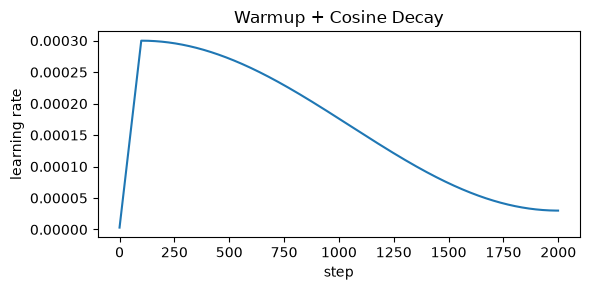

lr at step 0:                        3.00e-06
lr at step 100 (end of warmup):        3.00e-04
lr at step 1999 (end of schedule):     3.00e-05


In [27]:
def lr_schedule(step, warmup_steps, max_steps, base_lr, min_lr_ratio=0.1):
    if step < warmup_steps:
        return base_lr * (step + 1) / warmup_steps
    progress = min((step - warmup_steps) / max(1, max_steps - warmup_steps), 1.0)
    cosine = 0.5 * (1 + math.cos(math.pi * progress))
    return min_lr_ratio * base_lr + (1 - min_lr_ratio) * base_lr * cosine


warmup_steps, max_steps_demo, base_lr = 100, 2000, 3e-4
steps = np.arange(max_steps_demo)
lrs = [lr_schedule(s, warmup_steps, max_steps_demo, base_lr) for s in steps]

plt.figure(figsize=(6, 3))
plt.plot(steps, lrs)
plt.xlabel("step")
plt.ylabel("learning rate")
plt.title("Warmup + Cosine Decay")
plt.tight_layout()
plt.show()

print(f"lr at step 0:                        {lrs[0]:.2e}")
print(f"lr at step {warmup_steps} (end of warmup):        {lrs[warmup_steps]:.2e}")
print(f"lr at step {max_steps_demo - 1} (end of schedule):     {lrs[-1]:.2e}")

## 3.4 Gradient Clipping by Global Norm

Clips the combined norm across *all* parameter gradients (not per-parameter),
preserving the relative direction of the update while preventing rare large
gradients from destabilizing training.

In [28]:
def clip_grad_norm(params_and_grads, max_norm):
    total_sq = sum(np.sum(grad ** 2) for _, _, grad in params_and_grads)
    total_norm = math.sqrt(total_sq)
    if total_norm > max_norm:
        scale = max_norm / (total_norm + 1e-6)
        for _, _, grad in params_and_grads:
            grad *= scale
    return total_norm

## 3.5 Sanity Check: Single-Batch Overfitting

Before training on the full corpus, we confirm the entire pipeline works end to
end (forward, backward, optimizer) by overfitting a single fixed batch. If the
loss doesn't collapse toward zero, something is wrong in the wiring even if
every individual gradient check passed. A forgotten grad reset, a stale cache,
or an optimizer state bug are all invisible to gradchecking, which never runs
more than one step.

We also apply the cache-clearing discipline from the design doc explicitly:
every layer's cache is cleared after each optimizer step, so no stale
intermediate value can silently leak into the next step.


step    0 | loss 4.8372
step   50 | loss 0.0887
step  100 | loss 0.0063
step  150 | loss 0.0036
step  200 | loss 0.0025
step  250 | loss 0.0019
step  299 | loss 0.0015


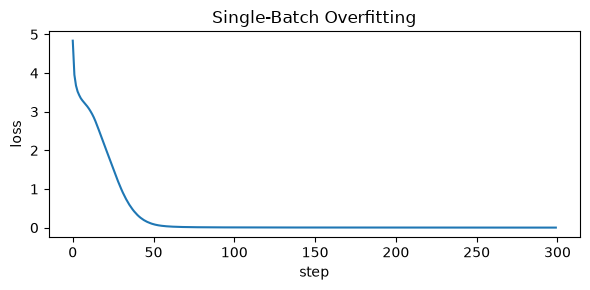


final loss: 0.0015 (started at 4.8372)
OK: the model can memorize a single batch.


In [29]:
def clear_all_caches(layer):
    layer.cache.clear()
    for sub in getattr(layer, 'sublayers', []):
        clear_all_caches(sub)


set_seed(SEED)
model = GPTModel(config)
params_and_grads = collect_params_grads(model)
optimizer = AdamW(params_and_grads, lr=config.learning_rate, weight_decay=config.weight_decay)

xb_fixed, yb_fixed = get_batch("train", config, batch_size=8)

overfit_losses = []
overfit_steps = 300

for step in range(overfit_steps):
    zero_all_grads(model)

    logits = model.forward(xb_fixed)
    loss, probs = cross_entropy_loss(logits, yb_fixed)
    dlogits = cross_entropy_backward(probs, yb_fixed)
    model.backward(dlogits)

    clip_grad_norm(params_and_grads, config.grad_clip_norm)
    optimizer.step()
    clear_all_caches(model)

    overfit_losses.append(loss)
    if step % 50 == 0 or step == overfit_steps - 1:
        print(f"step {step:4d} | loss {loss:.4f}")

plt.figure(figsize=(6, 3))
plt.plot(overfit_losses)
plt.xlabel("step")
plt.ylabel("loss")
plt.title("Single-Batch Overfitting")
plt.tight_layout()
plt.show()

print(f"\nfinal loss: {overfit_losses[-1]:.4f} (started at {overfit_losses[0]:.4f})")
assert overfit_losses[-1] < 0.5, "Failed to overfit a single batch -- likely a bug in the backward pass wiring"
print("OK: the model can memorize a single batch.")

## 3.6 Full Training Run

Trains on the real corpus with periodic validation loss estimation, global
gradient-norm logging (to catch vanishing/exploding gradients), and parameter
checkpointing at each evaluation point. The checkpoints let us compare
generation quality from early vs. late training in Phase 4.


In [30]:
def estimate_loss(model, config, eval_iters=10):
    """Average loss over several batches per split, without updating weights."""
    losses = {}
    for split in ["train", "val"]:
        split_losses = []
        for _ in range(eval_iters):
            xb, yb = get_batch(split, config)
            logits = model.forward(xb)
            loss, _ = cross_entropy_loss(logits, yb)
            split_losses.append(loss)
            clear_all_caches(model)
        losses[split] = float(np.mean(split_losses))
    return losses


def named_groups(model):
    """Top-level components for per-group gradient-norm diagnostics.

    pos_emb is skipped when it doesn't exist -- with RoPE enabled the model
    has no additive positional embedding at all.
    """
    groups = {"token_emb": model.token_emb, "ln_f": model.ln_f}
    if model.pos_emb is not None:
        groups["pos_emb"] = model.pos_emb
    for i, block in enumerate(model.blocks):
        groups[f"block{i}"] = block
    return groups


def grad_norm_by_group(model):
    """L2 gradient norm per top-level component -- diagnoses vanishing/exploding
    gradients by depth (are early blocks getting meaningfully smaller gradients
    than late blocks?).

    With weight tying there is no separate output-projection gradient to report:
    the output projection's contribution is accumulated into the token
    embedding's gradient, so it is already counted under "token_emb".
    """
    norms = {}
    for label, layer in named_groups(model).items():
        entries = collect_params_grads(layer)
        norms[label] = math.sqrt(sum(np.sum(g ** 2) for _, _, g in entries))
    if 'W_out' in model.grads:
        norms["output_proj"] = float(np.linalg.norm(model.grads['W_out']))
    return norms


def train(model, config, max_steps=None, log_interval=100, eval_interval=200, eval_iters=10):
    max_steps = max_steps or config.max_steps
    params_and_grads = collect_params_grads(model)
    optimizer = AdamW(params_and_grads, lr=config.learning_rate, weight_decay=config.weight_decay)

    history = {"step": [], "train_loss": [], "grad_norm": [],
               "val_step": [], "val_loss": [], "group_norms": []}
    checkpoints = {}

    for step in range(max_steps):
        lr = lr_schedule(step, config.warmup_steps, max_steps, config.learning_rate)
        optimizer.lr = lr

        zero_all_grads(model)
        xb, yb = get_batch("train", config)
        logits = model.forward(xb)
        loss, probs = cross_entropy_loss(logits, yb)
        dlogits = cross_entropy_backward(probs, yb)
        model.backward(dlogits)

        total_norm = clip_grad_norm(params_and_grads, config.grad_clip_norm)

        if step % eval_interval == 0 or step == max_steps - 1:
            history["group_norms"].append((step, grad_norm_by_group(model)))

        optimizer.step()
        clear_all_caches(model)

        history["step"].append(step)
        history["train_loss"].append(loss)
        history["grad_norm"].append(total_norm)

        if step % log_interval == 0 or step == max_steps - 1:
            print(f"step {step:5d} | lr {lr:.2e} | train loss {loss:.4f} | grad norm {total_norm:.3f}")

        if step % eval_interval == 0 or step == max_steps - 1:
            losses = estimate_loss(model, config, eval_iters=eval_iters)
            history["val_step"].append(step)
            history["val_loss"].append(losses["val"])
            print(f"           -> eval: train {losses['train']:.4f} | val {losses['val']:.4f}")
            checkpoints[step] = {name: p.copy() for name, p, g in params_and_grads}

    return history, checkpoints


## 3.7 Baseline Training Run

Trains the baseline configuration for 2000 steps. A full run takes roughly 85
minutes on CPU, so the result is cached in `runs/baseline.pkl` and reloaded on
subsequent executions. Set `RETRAIN = True` at the top of the notebook to force
training from scratch. Validation loss is estimated every 200 steps and
parameters are checkpointed at each of those points.


In [31]:
import pickle, os

RUNS_DIR = "runs"
_cache_path = os.path.join(RUNS_DIR, "baseline.pkl")

if not RETRAIN and os.path.exists(_cache_path):
    with open(_cache_path, "rb") as f:
        _cached = pickle.load(f)
    history, checkpoints = _cached["history"], _cached["checkpoints"]
    set_seed(SEED)
    model = GPTModel(config)
    print("Loaded cached baseline run from", _cache_path)
else:
    set_seed(SEED)
    model = GPTModel(config)
    history, checkpoints = train(model, config)
    os.makedirs(RUNS_DIR, exist_ok=True)
    with open(_cache_path, "wb") as f:
        pickle.dump({"history": history, "checkpoints": checkpoints, "config": config}, f)
    print("\nTraining complete, cached to", _cache_path)

Loaded cached baseline run from runs\baseline.pkl


# Phase 4 - Generation

## 4.1 Sampling Utilities

Four decoding strategies, all built on the same numerically stable softmax:
argmax (greedy), temperature scaling, top-k filtering, and top-p (nucleus)
filtering. Top-k and top-p can be combined with temperature scaling.


In [32]:
def stable_softmax(logits):
    """logits: (..., V). Stable softmax over the last axis."""
    shifted = logits - logits.max(axis=-1, keepdims=True)
    exp = np.exp(shifted)
    return exp / exp.sum(axis=-1, keepdims=True)


def top_k_filter(logits, k):
    """Mask out everything except the top-k logits per row (set to -inf)."""
    k = min(k, logits.shape[-1])
    threshold = np.sort(logits, axis=-1)[:, -k][:, None]
    return np.where(logits < threshold, -np.inf, logits)


def top_p_filter(logits, p):
    """Nucleus sampling: keep the smallest set of highest-probability tokens
    whose cumulative probability is >= p; renormalize over just that set."""
    probs = stable_softmax(logits)
    sort_idx = np.argsort(-probs, axis=-1)
    sorted_probs = np.take_along_axis(probs, sort_idx, axis=-1)
    cumulative = np.cumsum(sorted_probs, axis=-1)

    cutoff = cumulative > p
    cutoff[:, 1:] = cutoff[:, :-1].copy()  # shift right: always keep at least 1 token
    cutoff[:, 0] = False

    sorted_probs = np.where(cutoff, 0.0, sorted_probs)
    sorted_probs /= sorted_probs.sum(axis=-1, keepdims=True)

    probs_filtered = np.zeros_like(probs)
    np.put_along_axis(probs_filtered, sort_idx, sorted_probs, axis=-1)
    return probs_filtered


def sample_from_probs(probs):
    """probs: (1, V), already normalized (or close to it). Returns shape (1,)."""
    p = probs[0]
    p = p / p.sum()  # guard against tiny floating-point drift after filtering
    return np.array([np.random.choice(len(p), p=p)])

## 4.2 Autoregressive Generation Loop

At each step, the context window is cropped to the last `context_length`
tokens (the model has no memory beyond that), a forward pass produces the
next-token distribution, and one of the four strategies above picks the next
token. Caches are cleared after each forward call since generation never
calls `backward`.

In [33]:
def load_checkpoint(model, checkpoint):
    """Overwrite the model's current parameters in place with a saved checkpoint."""
    for name, param, grad in collect_params_grads(model):
        param[:] = checkpoint[name]


def generate(model, config, tokenizer, prompt="\n", max_new_tokens=300,
             temperature=1.0, top_k=None, top_p=None, greedy=False):
    ids = tokenizer.encode(prompt).reshape(1, -1)

    for _ in range(max_new_tokens):
        ids_cond = ids[:, -config.context_length:]
        logits = model.forward(ids_cond)
        clear_all_caches(model)
        next_logits = logits[:, -1, :]  # (1, V) -- distribution for the next token only

        if greedy:
            next_id = np.argmax(next_logits, axis=-1)
        else:
            scaled = next_logits / max(temperature, 1e-8)
            if top_k is not None:
                scaled = top_k_filter(scaled, top_k)
            probs = top_p_filter(scaled, top_p) if top_p is not None else stable_softmax(scaled)
            next_id = sample_from_probs(probs)

        ids = np.concatenate([ids, next_id.reshape(1, 1)], axis=1)

    return tokenizer.decode(ids[0])

## 4.3 Early vs. Late Checkpoint: Learning Progress Made Visible

Same prompt, same decoding settings, only the weights differ: the checkpoint
from right after training started vs. the fully trained model.


In [34]:
np.random.seed(42)
early_step = min(checkpoints.keys())
late_step = max(checkpoints.keys())

print(f"=== Early checkpoint (step {early_step}) ===")
load_checkpoint(model, checkpoints[early_step])
print(generate(model, config, tokenizer, prompt="ROMEO:", max_new_tokens=200, temperature=0.8))

print(f"\n=== Late checkpoint (step {late_step}) ===")
load_checkpoint(model, checkpoints[late_step])
print(generate(model, config, tokenizer, prompt="ROMEO:", max_new_tokens=200, temperature=0.8))

=== Early checkpoint (step 0) ===
ROMEO:Pyrp??$tiq!yrE?BHaaOp?OPfu?fq,p?,yyuK.uY?a!yJqPphIyuywpy!E'OPJwJJm;u.zuF
urut,P:wiJ&PPupxZ:rrpuihi!.!pIRwGarH,I;wupvu?wYuxJ.DKvu
PLC.IyJiuJyyAZHI!nO
JxH:JzDmtEuJoaT3uJ?!pr
OCqDrJy3J.xwHqugPH3xwaJJuwwu

=== Late checkpoint (step 1999) ===
ROMEO:
A wield and for this be fring.

KING RICHARD IIII:
What:
Say?

Shere, thou this hank king I have neZe.

VINGLONGhing EDY Setree.

PALENRIA:
No, no heave an not pisters ad and tere sours,
Three, would


## 4.4 Decoding Strategy Comparison (Fully Trained Model)

In [35]:
np.random.seed(42)
load_checkpoint(model, checkpoints[late_step])  # make sure we're on the final weights

print("=== Greedy ===")
print(generate(model, config, tokenizer, prompt="ROMEO:", max_new_tokens=200, greedy=True))

print("\n=== Temperature = 1.2 ===")
print(generate(model, config, tokenizer, prompt="ROMEO:", max_new_tokens=200, temperature=1.2))

print("\n=== Top-k = 10, temperature = 0.8 ===")
print(generate(model, config, tokenizer, prompt="ROMEO:", max_new_tokens=200, temperature=0.8, top_k=10))

print("\n=== Top-p = 0.9, temperature = 0.8 ===")
print(generate(model, config, tokenizer, prompt="ROMEO:", max_new_tokens=200, temperature=0.8, top_p=0.9))

=== Greedy ===
ROMEO:
There the shall the so the so the seep to the the so the seep to the
The the so the the see the the some the the the the
the should the the the the they beart then
That the the the sof thee the the s

=== Temperature = 1.2 ===
ROMEO:
You a tis you, doche, for lian'but;
And lay pirfetser. Be be's foll you
spir, I. Ram ppricked; he Pasins grace wors?
This KentrI haime muntwer'd no exd;
thereiglincle I o'gholift favilling attheress.

=== Top-k = 10, temperature = 0.8 ===
ROMEO:
A wif take thing streak hose the do and; what would hath seet
To the thou or stran sand sair be foold,
To it mady than somen's in teak the me mear
To than any his thou a a sand thee too cout.

Citize

=== Top-p = 0.9, temperature = 0.8 ===
ROMEO:
Why what how shall to man.

CARINCHARD BOLA:
You sir, in I and your way thou with orte worn
In payse his to so to all be would as yourse
The dom both they bather againt my now
Yet will am can his cal


# Phase 5 - Modernization

## 5.1 RMSNorm

RMSNorm (Zhang & Sennrich, 2019) drops LayerNorm's mean-centering step
entirely and scales purely by the root-mean-square of the activations. No
`beta` parameter and no mean subtraction, so it is cheaper to compute, and it
empirically matches LayerNorm's quality in modern LLMs (LLaMA, Mistral).

    rms(x) = sqrt(mean(x^2) + eps)
    x_hat  = x / rms(x)
    out    = gamma * x_hat


In [36]:
class RMSNorm(Layer):
    def __init__(self, d_model, eps=1e-5):
        super().__init__()
        self.eps = eps
        self.params['gamma'] = np.ones(d_model, dtype=DTYPE)
        self.grads['gamma'] = np.zeros_like(self.params['gamma'])

    def forward(self, x):
        d = x.shape[-1]
        ms = np.mean(x ** 2, axis=-1, keepdims=True)
        rms = np.sqrt(ms + self.eps)
        x_hat = x / rms
        out = self.params['gamma'] * x_hat
        self.cache.update(dict(x_hat=x_hat, rms=rms))
        return out

    def backward(self, dout):
        """rms(x) depends on every element of x (via the mean of squares), so
        -- structurally identical to LayerNorm's dx -- there is a direct term
        plus a correction term. Unlike LayerNorm there is only ONE correction
        term (for the scale), since RMSNorm never subtracts a mean:

            dgamma = sum(dout * x_hat)                        over leading dims
            dx_hat = dout * gamma
            dx     = (1/rms) * ( dx_hat - (x_hat/d) * sum(dx_hat * x_hat) )
        """
        x_hat, rms = self.cache['x_hat'], self.cache['rms']
        d = x_hat.shape[-1]

        reduce_axes = tuple(range(dout.ndim - 1))
        self.grads['gamma'] += np.sum(dout * x_hat, axis=reduce_axes)

        dx_hat = dout * self.params['gamma']
        sum_term = np.sum(dx_hat * x_hat, axis=-1, keepdims=True)
        dx = (dx_hat - (x_hat / d) * sum_term) / rms
        return dx

## 5.2 Verify: RMSNorm Gradient Check

In [37]:
np.random.seed(8)
B_t, T_t, D_t = 2, 3, 4
x_test = np.random.randn(B_t, T_t, D_t).astype(np.float64)
dout_test = np.random.randn(B_t, T_t, D_t).astype(np.float64)

rms_test = RMSNorm(D_t)
rms_test.params['gamma'] = np.random.randn(D_t).astype(np.float64)
rms_test.grads['gamma'] = np.zeros_like(rms_test.params['gamma'])

def reset_rms_grads():
    rms_test.grads['gamma'][:] = 0

def forward_and_score(x):
    return np.sum(dout_test * rms_test.forward(x))

reset_rms_grads()
rms_test.forward(x_test)
dx_analytic = rms_test.backward(dout_test)
gradcheck(lambda: forward_and_score(x_test), x_test, dx_analytic, name="RMSNorm dx")

reset_rms_grads()
rms_test.forward(x_test)
rms_test.backward(dout_test)
dgamma_analytic = rms_test.grads['gamma'].copy()
gradcheck(lambda: forward_and_score(x_test), rms_test.params['gamma'], dgamma_analytic, name="RMSNorm dgamma")

[OK] RMSNorm dx: max relative error over 20 checks = 1.22e-09
[OK] RMSNorm dgamma: max relative error over 20 checks = 1.33e-11


np.True_

## 5.3 Training Run: RMSNorm Variant

Same config as the baseline, only `use_rmsnorm=True`. Kept as a separate model
and history so the baseline run stays available for the Phase 6 comparison.

In [38]:
import dataclasses

_cache_path = os.path.join(RUNS_DIR, "rmsnorm.pkl")

config_rmsnorm = dataclasses.replace(config, use_rmsnorm=True)

if not RETRAIN and os.path.exists(_cache_path):
    with open(_cache_path, "rb") as f:
        _cached = pickle.load(f)
    history_rmsnorm, checkpoints_rmsnorm = _cached["history"], _cached["checkpoints"]
    set_seed(SEED)
    model_rmsnorm = GPTModel(config_rmsnorm)
    print("Loaded cached RMSNorm run from", _cache_path)
else:
    set_seed(SEED)
    model_rmsnorm = GPTModel(config_rmsnorm)
    history_rmsnorm, checkpoints_rmsnorm = train(model_rmsnorm, config_rmsnorm)
    with open(_cache_path, "wb") as f:
        pickle.dump({"history": history_rmsnorm, "checkpoints": checkpoints_rmsnorm, "config": config_rmsnorm}, f)
    print("\nRMSNorm training complete, cached to", _cache_path)

Loaded cached RMSNorm run from runs\rmsnorm.pkl


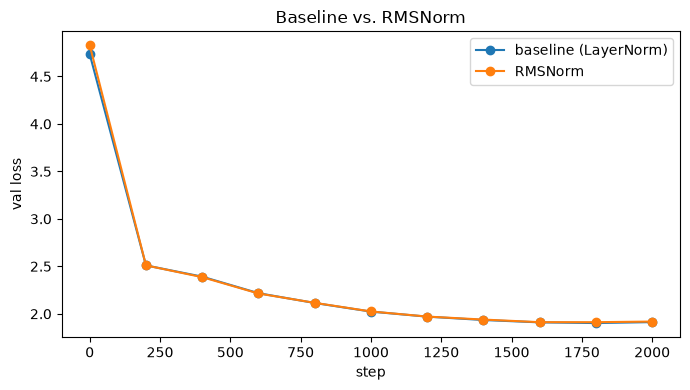

baseline final val loss: 1.9125
RMSNorm  final val loss: 1.9184


In [39]:
plt.figure(figsize=(7, 4))
plt.plot(history["val_step"], history["val_loss"], marker='o', label="baseline (LayerNorm)")
plt.plot(history_rmsnorm["val_step"], history_rmsnorm["val_loss"], marker='o', label="RMSNorm")
plt.xlabel("step")
plt.ylabel("val loss")
plt.title("Baseline vs. RMSNorm")
plt.legend()
plt.tight_layout()
plt.show()

print(f"baseline final val loss: {history['val_loss'][-1]:.4f}")
print(f"RMSNorm  final val loss: {history_rmsnorm['val_loss'][-1]:.4f}")

## 5.4 SwiGLU

SwiGLU (Shazeer, 2020) replaces the single ReLU-gated feedforward with a
gated linear unit. Instead of one "up" projection there are two parallel ones:
a gate branch passed through Swish (`Swish(z) = z*sigmoid(z)`, aka SiLU) and a
value branch, multiplied elementwise, then projected back down.

    SwiGLU(x) = (Swish(x*W1) (*) (x*W3)) * W2

No biases, matching common modern practice (LLaMA/Mistral).

One caveat on the ablation's fairness: with three weight matrices instead of
the ReLU-FFN's two, this variant has more parameters at the same `d_ff`. A
strictly parameter-matched comparison would scale `d_ff` down by about a third
for SwiGLU. We keep `d_ff` identical for simplicity, and Phase 6 reports the
parameter counts alongside the losses so the cost is visible.


In [40]:
class SwiGLU(Layer):
    def __init__(self, d_model, d_ff):
        super().__init__()
        s1 = 1.0 / math.sqrt(d_model)
        s2 = 1.0 / math.sqrt(d_ff)
        self.params['W1'] = (np.random.randn(d_model, d_ff) * s1).astype(DTYPE)  # gate
        self.params['W3'] = (np.random.randn(d_model, d_ff) * s1).astype(DTYPE)  # value
        self.params['W2'] = (np.random.randn(d_ff, d_model) * s2).astype(DTYPE)  # down-projection
        for name in ['W1', 'W3', 'W2']:
            self.grads[name] = np.zeros_like(self.params[name])

    def forward(self, x):
        z1 = x @ self.params['W1']
        sig = 1.0 / (1.0 + np.exp(-z1))
        gate = z1 * sig            # Swish(z1)
        value = x @ self.params['W3']
        h = gate * value
        out = h @ self.params['W2']
        self.cache.update(dict(x=x, z1=z1, sig=sig, value=value, h=h))
        return out

    def backward(self, dout):
        """Swish'(z) = sigma(z) + z*sigma(z)*(1-sigma(z)) (product rule on
        z*sigma(z)), then the gating product rule, then standard linear
        backward for each of the three matrices.
        """
        x, z1, sig, value, h = (self.cache[k] for k in ['x', 'z1', 'sig', 'value', 'h'])
        gate = z1 * sig

        self.grads['W2'] += np.einsum('btf,btd->fd', h, dout)
        dh = dout @ self.params['W2'].T

        dgate = dh * value
        dvalue = dh * gate

        dswish = sig + z1 * sig * (1 - sig)
        dz1 = dgate * dswish

        self.grads['W1'] += np.einsum('btd,btf->df', x, dz1)
        self.grads['W3'] += np.einsum('btd,btf->df', x, dvalue)

        dx = dz1 @ self.params['W1'].T + dvalue @ self.params['W3'].T
        return dx

## 5.5 Verify: SwiGLU Gradient Check

In [41]:
np.random.seed(9)
B_t, T_t, D_t, F_t = 2, 3, 4, 6
x_test = np.random.randn(B_t, T_t, D_t).astype(np.float64)
dout_test = np.random.randn(B_t, T_t, D_t).astype(np.float64)

swiglu_test = SwiGLU(D_t, F_t)
for name in swiglu_test.params:
    swiglu_test.params[name] = np.random.randn(*swiglu_test.params[name].shape).astype(np.float64)
    swiglu_test.grads[name] = np.zeros_like(swiglu_test.params[name])

def reset_swiglu_grads():
    for name in swiglu_test.grads:
        swiglu_test.grads[name][:] = 0

def forward_and_score(x):
    return np.sum(dout_test * swiglu_test.forward(x))

reset_swiglu_grads()
swiglu_test.forward(x_test)
dx_analytic = swiglu_test.backward(dout_test)
gradcheck(lambda: forward_and_score(x_test), x_test, dx_analytic, name="SwiGLU dx")

for pname in ['W1', 'W3', 'W2']:
    reset_swiglu_grads()
    swiglu_test.forward(x_test)
    swiglu_test.backward(dout_test)
    analytic = swiglu_test.grads[pname].copy()
    gradcheck(lambda: forward_and_score(x_test), swiglu_test.params[pname], analytic, name=f"SwiGLU d{pname}")

[OK] SwiGLU dx: max relative error over 20 checks = 4.83e-10
[OK] SwiGLU dW1: max relative error over 20 checks = 2.33e-09
[OK] SwiGLU dW3: max relative error over 20 checks = 5.47e-10
[OK] SwiGLU dW2: max relative error over 20 checks = 2.39e-10


In [42]:
_cache_path = os.path.join(RUNS_DIR, "rms_swiglu.pkl")

config_rms_swiglu = dataclasses.replace(config, use_rmsnorm=True, use_swiglu=True)

if not RETRAIN and os.path.exists(_cache_path):
    with open(_cache_path, "rb") as f:
        _cached = pickle.load(f)
    history_rms_swiglu, checkpoints_rms_swiglu = _cached["history"], _cached["checkpoints"]
    set_seed(SEED)
    model_rms_swiglu = GPTModel(config_rms_swiglu)
    print("Loaded cached RMSNorm+SwiGLU run from", _cache_path)
else:
    set_seed(SEED)
    model_rms_swiglu = GPTModel(config_rms_swiglu)
    history_rms_swiglu, checkpoints_rms_swiglu = train(model_rms_swiglu, config_rms_swiglu)
    with open(_cache_path, "wb") as f:
        pickle.dump({"history": history_rms_swiglu, "checkpoints": checkpoints_rms_swiglu, "config": config_rms_swiglu}, f)
    print("\nRMSNorm+SwiGLU training complete, cached to", _cache_path)

Loaded cached RMSNorm+SwiGLU run from runs\rms_swiglu.pkl


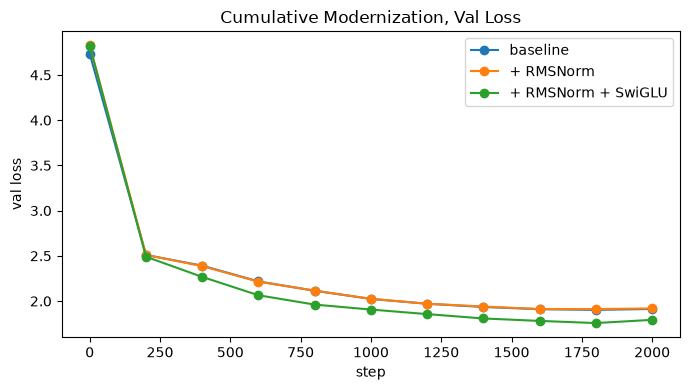

baseline final val loss:          1.9125
+RMSNorm final val loss:          1.9184
+RMSNorm+SwiGLU final val loss:   1.7923


In [43]:
plt.figure(figsize=(7, 4))
plt.plot(history["val_step"], history["val_loss"], marker='o', label="baseline")
plt.plot(history_rmsnorm["val_step"], history_rmsnorm["val_loss"], marker='o', label="+ RMSNorm")
plt.plot(history_rms_swiglu["val_step"], history_rms_swiglu["val_loss"], marker='o', label="+ RMSNorm + SwiGLU")
plt.xlabel("step")
plt.ylabel("val loss")
plt.title("Cumulative Modernization, Val Loss")
plt.legend()
plt.tight_layout()
plt.show()

print(f"baseline final val loss:          {history['val_loss'][-1]:.4f}")
print(f"+RMSNorm final val loss:          {history_rmsnorm['val_loss'][-1]:.4f}")
print(f"+RMSNorm+SwiGLU final val loss:   {history_rms_swiglu['val_loss'][-1]:.4f}")

## 5.6 RoPE: Rotary Position Embeddings

RoPE (Su et al., 2021) encodes position by **rotating** the query and key
vectors in 2D subspaces, rather than adding a position vector to the token
embedding. Each pair of head dimensions is treated as a complex plane and
rotated by an angle proportional to the token's position:

    theta_i = 1 / base^(2i / d_head)        (frequency for dimension pair i)
    angle   = position * theta_i

The dot product of two rotated vectors depends only on the *difference* of
their rotation angles. So the attention score between positions `m` and `n`
becomes a function of `m - n`, and relative position information falls out of
the dot product for free, with no learned position parameters at all.

Implementation note: we use the LLaMA-style "rotate half" layout, pairing
dimensions `[0, d/2)` with `[d/2, d)` rather than using interleaved pairs. Both
are valid and equivalent up to a permutation of the head dimensions.


In [44]:
class RoPE(Layer):
    """Rotary position embeddings, applied to a (B, H, T, d_head) tensor.

    Parameter-free: the rotation angles are fixed functions of position, so
    there is nothing to learn and nothing to gradient-check w.r.t. parameters.
    The angle table is precomputed once for the full context length and sliced
    per forward call.

    `dtype` is exposed so property-based tests can build the angle tables at
    float64 precision. Casting the tables to float64 *after* they have been
    rounded to float32 does not recover the lost precision -- the tables must
    be built at the target precision from the start.
    """

    def __init__(self, d_head, context_length, base=10000.0, dtype=DTYPE):
        super().__init__()
        assert d_head % 2 == 0, "RoPE requires an even head dimension"
        self.d_head = d_head
        self.half = d_head // 2

        inv_freq = 1.0 / (base ** (np.arange(0, self.half, dtype=np.float64) / self.half))
        positions = np.arange(context_length, dtype=np.float64)
        angles = positions[:, None] * inv_freq[None, :]      # (context_length, half)

        self.cos_table = np.cos(angles).astype(dtype)
        self.sin_table = np.sin(angles).astype(dtype)

    def forward(self, x):
        """x: (B, H, T, d_head). Rotates the first half against the second."""
        T = x.shape[2]
        cos = self.cos_table[:T][None, None, :, :]   # (1,1,T,half)
        sin = self.sin_table[:T][None, None, :, :]

        x1, x2 = x[..., :self.half], x[..., self.half:]
        out1 = x1 * cos - x2 * sin
        out2 = x1 * sin + x2 * cos

        self.cache.update(dict(cos=cos, sin=sin))
        return np.concatenate([out1, out2], axis=-1)

    def backward(self, dout):
        """A rotation by a fixed angle is a linear, orthogonal map, so its
        backward is the transpose of the rotation matrix -- i.e. the inverse
        rotation (angle negated):

            forward:  [out1] = [cos  -sin] [x1]
                      [out2]   [sin   cos] [x2]

            backward: [dx1]  = [ cos  sin] [dout1]
                      [dx2]    [-sin  cos] [dout2]

        The angles are not parameters, so they receive no gradient.
        """
        cos, sin = self.cache['cos'], self.cache['sin']
        d1, d2 = dout[..., :self.half], dout[..., self.half:]

        dx1 = d1 * cos + d2 * sin
        dx2 = -d1 * sin + d2 * cos
        return np.concatenate([dx1, dx2], axis=-1)

## 5.7 Verify: RoPE Gradient Check and Rotation Properties

Three checks, two of which are property-based rather than gradient-based:

1. The backward pass (`dx`), a standard numerical gradient check.
2. **Norm preservation.** A rotation must not change vector lengths.
3. **Relative-position dependence**, the defining property of RoPE: the dot
   product between a rotated query at position `m` and a rotated key at
   position `n` must depend only on `m - n`. We verify this empirically by
   checking that two position pairs with the same offset produce identical dot
   products.

Property tests matter here because a gradient check alone cannot catch a
*consistently wrong* rotation: an incorrect sign or dimension pairing still
has a perfectly consistent derivative. The tests are run with float64 angle
tables so that the tolerances reflect genuine algebraic correctness rather
than float32 rounding noise.


In [45]:
np.random.seed(10)
B_t, H_t, T_t, Dh_t = 2, 2, 5, 4
x_test = np.random.randn(B_t, H_t, T_t, Dh_t).astype(np.float64)
dout_test = np.random.randn(B_t, H_t, T_t, Dh_t).astype(np.float64)

# build the angle tables at float64 from the start (see class docstring)
rope_test = RoPE(Dh_t, context_length=T_t, dtype=np.float64)

def forward_and_score(x):
    return np.sum(dout_test * rope_test.forward(x))

rope_test.forward(x_test)
dx_analytic = rope_test.backward(dout_test)
gradcheck(lambda: forward_and_score(x_test), x_test, dx_analytic, name="RoPE dx")

# --- property test 1: rotation preserves vector norms ---
rotated = rope_test.forward(x_test)
max_norm_dev = np.max(np.abs(np.linalg.norm(x_test, axis=-1) - np.linalg.norm(rotated, axis=-1)))
print(f"[{'OK' if max_norm_dev < 1e-12 else 'FAIL'}] RoPE norm preservation: max deviation = {max_norm_dev:.2e}")

# --- property test 2: dot product depends only on relative position ---
v = np.random.randn(Dh_t)
w = np.random.randn(Dh_t)
seq = np.zeros((1, 1, T_t, Dh_t))

seq[0, 0, :, :] = v
rot_v = rope_test.forward(seq.copy())[0, 0]
seq[0, 0, :, :] = w
rot_w = rope_test.forward(seq.copy())[0, 0]

dot_0_2 = rot_v[0] @ rot_w[2]
dot_2_4 = rot_v[2] @ rot_w[4]
dev = abs(dot_0_2 - dot_2_4)
print(f"[{'OK' if dev < 1e-12 else 'FAIL'}] RoPE relative-position property: "
      f"<q_0,k_2> = {dot_0_2:.12f} vs <q_2,k_4> = {dot_2_4:.12f} (dev = {dev:.2e})")

[OK] RoPE dx: max relative error over 20 checks = 2.82e-10
[OK] RoPE norm preservation: max deviation = 8.88e-16
[OK] RoPE relative-position property: <q_0,k_2> = 3.868613188532 vs <q_2,k_4> = 3.868613188532 (dev = 0.00e+00)


## 5.8 Wiring RoPE into Attention

RoPE is applied to `q` and `k` **after** the head split and **before** the
score computation. Two consequences for the backward pass:

- What gets cached as `q` and `k` are the *rotated* tensors, because that is
  what the score computation consumes. So `dq = dscores @ k_rot`, and `dk`
  correspondingly uses `q_rot`.
- The incoming `dq`/`dk` are gradients w.r.t. the *rotated* vectors, so they
  must be passed back through `RoPE.backward` (the inverse rotation) before
  being propagated to `Wq`/`Wk`.

`v` is **not** rotated. RoPE only encodes position in the query-key
interaction, which is where relative position matters.

Two separate `RoPE` instances are used for `q` and `k` rather than one shared
instance. The rotation is parameter-free and the angle tables are identical, so
sharing would be mathematically fine, but separate instances keep the cache
discipline unambiguous: each `forward` has exactly one matching `backward`, with
no possibility of one overwriting the other's cached values.


## 5.9 Verify: End-to-End Gradient Check on the Modern Architecture

The isolated RoPE check verified the rotation itself. This one verifies the
*integration*, that the rotated tensors are cached correctly and that the
inverse rotation is applied at the right point in the backward chain. Run on
the full modern configuration (RMSNorm + SwiGLU + RoPE) so all three
replacements are checked together.


In [46]:
def cast_rope_tables_to_float64(layer):
    """RoPE angle tables are built at DTYPE (float32); for the float64
    end-to-end check they must be rebuilt at float64, not cast after the fact
    (see RoPE docstring)."""
    if isinstance(layer, RoPE):
        rebuilt = RoPE(layer.d_head, layer.cos_table.shape[0], dtype=np.float64)
        layer.cos_table = rebuilt.cos_table
        layer.sin_table = rebuilt.sin_table
    for sub in getattr(layer, 'sublayers', []):
        cast_rope_tables_to_float64(sub)


np.random.seed(11)
tiny_modern = GPTConfig(
    vocab_size=6, context_length=4, n_layers=2, n_heads=2, d_model=4, d_ff=8,
    use_rmsnorm=True, use_swiglu=True, use_rope=True,
)
model_test = GPTModel(tiny_modern)
cast_params_to_float64(model_test)
cast_rope_tables_to_float64(model_test)

ids_test = np.random.randint(0, tiny_modern.vocab_size, size=(2, 4))
targets_test = np.random.randint(0, tiny_modern.vocab_size, size=(2, 4))

def full_model_loss():
    logits = model_test.forward(ids_test)
    loss, _ = cross_entropy_loss(logits, targets_test)
    return loss

zero_all_grads(model_test)
logits = model_test.forward(ids_test)
loss, probs = cross_entropy_loss(logits, targets_test)
model_test.backward(cross_entropy_backward(probs, targets_test))

all_passed = True
for name, param, grad in collect_params_grads(model_test):
    ok = gradcheck(full_model_loss, param, grad, num_checks=5, name=name)
    all_passed = all_passed and ok

print("\nALL PASSED (modern architecture):", all_passed)

[OK] GPTModel.W_out: max relative error over 5 checks = 1.46e-09
[OK] GPTModel[0].Embedding.weight: max relative error over 5 checks = 7.62e-06
[OK] GPTModel[1].TransformerBlock[0].RMSNorm.gamma: max relative error over 5 checks = 2.49e-09
[OK] GPTModel[1].TransformerBlock[1].CausalSelfAttention.Wq: max relative error over 5 checks = 1.42e-09
[OK] GPTModel[1].TransformerBlock[1].CausalSelfAttention.Wk: max relative error over 5 checks = 3.72e-10
[OK] GPTModel[1].TransformerBlock[1].CausalSelfAttention.Wv: max relative error over 5 checks = 1.18e-10
[OK] GPTModel[1].TransformerBlock[1].CausalSelfAttention.Wo: max relative error over 5 checks = 2.71e-10
[OK] GPTModel[1].TransformerBlock[2].RMSNorm.gamma: max relative error over 5 checks = 1.76e-10
[OK] GPTModel[1].TransformerBlock[3].SwiGLU.W1: max relative error over 5 checks = 2.29e-10
[OK] GPTModel[1].TransformerBlock[3].SwiGLU.W3: max relative error over 5 checks = 2.02e-10
[OK] GPTModel[1].TransformerBlock[3].SwiGLU.W2: max relative

In [47]:
_cache_path = os.path.join(RUNS_DIR, "rms_swiglu_rope.pkl")

config_rms_swiglu_rope = dataclasses.replace(
    config, use_rmsnorm=True, use_swiglu=True, use_rope=True
)

if not RETRAIN and os.path.exists(_cache_path):
    with open(_cache_path, "rb") as f:
        _cached = pickle.load(f)
    history_rsr, checkpoints_rsr = _cached["history"], _cached["checkpoints"]
    set_seed(SEED)
    model_rsr = GPTModel(config_rms_swiglu_rope)
    print("Loaded cached RMSNorm+SwiGLU+RoPE run from", _cache_path)
else:
    set_seed(SEED)
    model_rsr = GPTModel(config_rms_swiglu_rope)
    history_rsr, checkpoints_rsr = train(model_rsr, config_rms_swiglu_rope)
    with open(_cache_path, "wb") as f:
        pickle.dump({"history": history_rsr, "checkpoints": checkpoints_rsr, "config": config_rms_swiglu_rope}, f)
    print("\nRMSNorm+SwiGLU+RoPE training complete, cached to", _cache_path)

Loaded cached RMSNorm+SwiGLU+RoPE run from runs\rms_swiglu_rope.pkl


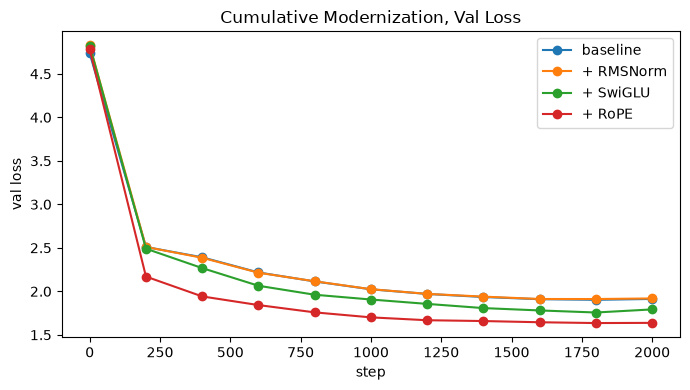

baseline     final val loss: 1.9125
+RMSNorm     final val loss: 1.9184
+SwiGLU      final val loss: 1.7923
+RoPE        final val loss: 1.6376


In [48]:
plt.figure(figsize=(7, 4))
plt.plot(history["val_step"], history["val_loss"], marker='o', label="baseline")
plt.plot(history_rmsnorm["val_step"], history_rmsnorm["val_loss"], marker='o', label="+ RMSNorm")
plt.plot(history_rms_swiglu["val_step"], history_rms_swiglu["val_loss"], marker='o', label="+ SwiGLU")
plt.plot(history_rsr["val_step"], history_rsr["val_loss"], marker='o', label="+ RoPE")
plt.xlabel("step")
plt.ylabel("val loss")
plt.title("Cumulative Modernization, Val Loss")
plt.legend()
plt.tight_layout()
plt.show()

for label, h in [("baseline", history), ("+RMSNorm", history_rmsnorm),
                 ("+SwiGLU", history_rms_swiglu), ("+RoPE", history_rsr)]:
    print(f"{label:12s} final val loss: {h['val_loss'][-1]:.4f}")

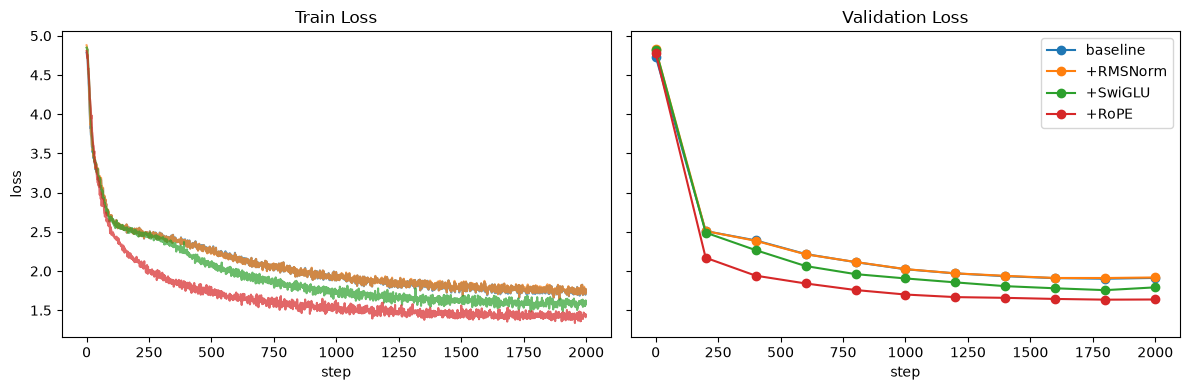

variant                   train      val      gap
baseline                 1.7349   1.9125   0.1776
+RMSNorm                 1.7401   1.9184   0.1783
+SwiGLU                  1.5754   1.7923   0.2169
+RoPE                    1.4446   1.6376   0.1931


In [49]:
runs = [("baseline", history), ("+RMSNorm", history_rmsnorm),
        ("+SwiGLU", history_rms_swiglu), ("+RoPE", history_rsr)]

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

for label, h in runs:
    axes[0].plot(h["step"], h["train_loss"], alpha=0.7, label=label)
    axes[1].plot(h["val_step"], h["val_loss"], marker='o', label=label)

axes[0].set_title("Train Loss"); axes[0].set_xlabel("step"); axes[0].set_ylabel("loss")
axes[1].set_title("Validation Loss"); axes[1].set_xlabel("step")
axes[1].legend()
plt.tight_layout()
plt.show()

print(f"{'variant':22s} {'train':>8s} {'val':>8s} {'gap':>8s}")
for label, h in runs:
    tr, va = h["train_loss"][-1], h["val_loss"][-1]
    print(f"{label:22s} {tr:>8.4f} {va:>8.4f} {va - tr:>8.4f}")

## 5.10 Weight Tying

The output projection reuses the token embedding matrix, transposed, instead of
maintaining a separate `(d_model, vocab_size)` matrix. The intuition: the
embedding maps token ids into the model's representation space, and the output
projection scores representations against tokens. Both operations relate the
same two spaces, so sharing one matrix is a reasonable inductive bias, and it
saves `d_model * vocab_size = 128 * 65 = 8,320` parameters here.

The subtlety is in the backward pass. The tied matrix is now used **twice** in
the forward pass, once for the embedding lookup and once for the output
projection, so it receives gradient contributions along **two independent
paths**, and those contributions must be **added**:

    dW_emb  =  (contribution from the output projection)
             + (contribution from the embedding lookup)

Overwriting instead of accumulating is the classic bug here. The model still
trains and the loss still decreases, so nothing looks obviously broken. Only
the gradient is silently wrong. The end-to-end gradient check is what catches
it.

One side effect worth noting: the tied matrix now carries the token
embedding's initialization scale (`0.02`) into the output projection, where the
untied version used `1/sqrt(d_model) ~ 0.088`. This changes the initial logit
scale and therefore the initial loss.


## 5.11 Verify: End-to-End Gradient Check on the Full Modern Architecture

All four replacements active. This check is the one that would catch a
two-path accumulation error in the tied embedding gradient. The isolated
component checks cannot, because the sharing only exists at the model level.


In [50]:
np.random.seed(12)
tiny_full = GPTConfig(
    vocab_size=6, context_length=4, n_layers=2, n_heads=2, d_model=4, d_ff=8,
    use_rmsnorm=True, use_swiglu=True, use_rope=True, use_weight_tying=True,
)
model_test = GPTModel(tiny_full)
cast_params_to_float64(model_test)
cast_rope_tables_to_float64(model_test)

ids_test = np.random.randint(0, tiny_full.vocab_size, size=(2, 4))
targets_test = np.random.randint(0, tiny_full.vocab_size, size=(2, 4))

def full_model_loss():
    logits = model_test.forward(ids_test)
    loss, _ = cross_entropy_loss(logits, targets_test)
    return loss

zero_all_grads(model_test)
logits = model_test.forward(ids_test)
loss, probs = cross_entropy_loss(logits, targets_test)
model_test.backward(cross_entropy_backward(probs, targets_test))

all_passed = True
for name, param, grad in collect_params_grads(model_test):
    ok = gradcheck(full_model_loss, param, grad, num_checks=8, name=name)
    all_passed = all_passed and ok

print("\nALL PASSED (full modern architecture, weight-tied):", all_passed)

[OK] GPTModel[0].Embedding.weight: max relative error over 8 checks = 7.58e-07
[OK] GPTModel[1].TransformerBlock[0].RMSNorm.gamma: max relative error over 8 checks = 1.78e-09
[OK] GPTModel[1].TransformerBlock[1].CausalSelfAttention.Wq: max relative error over 8 checks = 1.54e-09
[OK] GPTModel[1].TransformerBlock[1].CausalSelfAttention.Wk: max relative error over 8 checks = 8.62e-09
[OK] GPTModel[1].TransformerBlock[1].CausalSelfAttention.Wv: max relative error over 8 checks = 5.51e-09
[OK] GPTModel[1].TransformerBlock[1].CausalSelfAttention.Wo: max relative error over 8 checks = 1.05e-08
[OK] GPTModel[1].TransformerBlock[2].RMSNorm.gamma: max relative error over 8 checks = 9.54e-10
[OK] GPTModel[1].TransformerBlock[3].SwiGLU.W1: max relative error over 8 checks = 1.37e-08
[OK] GPTModel[1].TransformerBlock[3].SwiGLU.W3: max relative error over 8 checks = 6.06e-08
[OK] GPTModel[1].TransformerBlock[3].SwiGLU.W2: max relative error over 8 checks = 3.55e-09
[OK] GPTModel[2].TransformerBlock

## 5.12 Parameter Count Comparison

A concrete accounting of what each architectural change costs or saves.

In [51]:
def count_params(model):
    return sum(p.size for _, p, _ in collect_params_grads(model))

variants = [
    ("baseline",                    config),
    ("+RMSNorm",                    config_rmsnorm),
    ("+RMSNorm+SwiGLU",             config_rms_swiglu),
    ("+RMSNorm+SwiGLU+RoPE",        config_rms_swiglu_rope),
    ("+ all four (weight-tied)",    dataclasses.replace(config_rms_swiglu_rope, use_weight_tying=True)),
]

print(f"{'variant':30s} {'params':>10s}")
for label, cfg in variants:
    set_seed(SEED)
    m = GPTModel(cfg)
    print(f"{label:30s} {count_params(m):>10,d}")

variant                            params
baseline                          824,320
+RMSNorm                          823,168
+RMSNorm+SwiGLU                 1,082,752
+RMSNorm+SwiGLU+RoPE            1,066,368
+ all four (weight-tied)        1,058,048


## 5.13 Training Run: Full Modern Architecture

All four replacements active: RMSNorm, SwiGLU, RoPE, weight tying. This is the
final architecture, and the fifth and last data point of the ablation.

In [52]:
_cache_path = os.path.join(RUNS_DIR, "full.pkl")

config_full = dataclasses.replace(
    config, use_rmsnorm=True, use_swiglu=True, use_rope=True, use_weight_tying=True
)

if not RETRAIN and os.path.exists(_cache_path):
    with open(_cache_path, "rb") as f:
        _cached = pickle.load(f)
    history_full, checkpoints_full = _cached["history"], _cached["checkpoints"]
    set_seed(SEED)
    model_full = GPTModel(config_full)
    print("Loaded cached full-architecture run from", _cache_path)
else:
    set_seed(SEED)
    model_full = GPTModel(config_full)
    history_full, checkpoints_full = train(model_full, config_full)
    with open(_cache_path, "wb") as f:
        pickle.dump({"history": history_full, "checkpoints": checkpoints_full, "config": config_full}, f)
    print("\nFull modern architecture training complete, cached to", _cache_path)

Loaded cached full-architecture run from runs\full.pkl


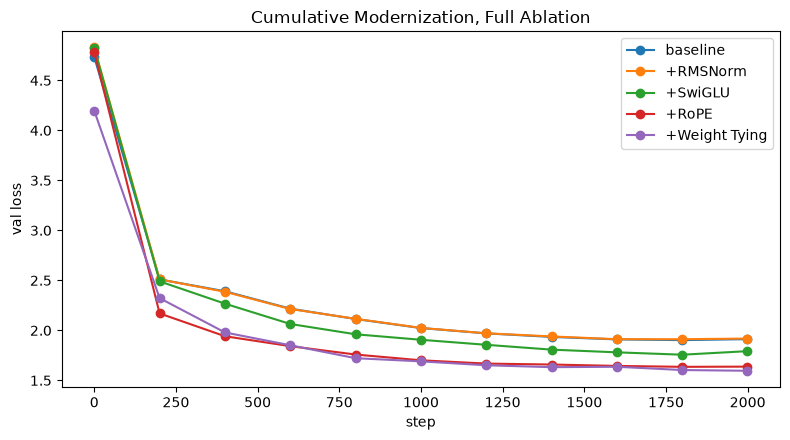

variant               train      val      gap      params
baseline             1.7349   1.9125   0.1776     824,320
+RMSNorm             1.7401   1.9184   0.1783     823,168
+SwiGLU              1.5754   1.7923   0.2169   1,082,752
+RoPE                1.4446   1.6376   0.1931   1,066,368
+Weight Tying        1.4403   1.5961   0.1559   1,058,048


In [53]:
runs = [
    ("baseline",        history,           config),
    ("+RMSNorm",        history_rmsnorm,   config_rmsnorm),
    ("+SwiGLU",         history_rms_swiglu, config_rms_swiglu),
    ("+RoPE",           history_rsr,       config_rms_swiglu_rope),
    ("+Weight Tying",   history_full,      config_full),
]

plt.figure(figsize=(8, 4.5))
for label, h, _ in runs:
    plt.plot(h["val_step"], h["val_loss"], marker='o', label=label)
plt.xlabel("step")
plt.ylabel("val loss")
plt.title("Cumulative Modernization, Full Ablation")
plt.legend()
plt.tight_layout()
plt.savefig("full_ablation.pdf", bbox_inches="tight")
plt.show()

print(f"{'variant':18s} {'train':>8s} {'val':>8s} {'gap':>8s} {'params':>11s}")
for label, h, cfg in runs:
    set_seed(SEED)
    n = count_params(GPTModel(cfg))
    tr, va = h["train_loss"][-1], h["val_loss"][-1]
    print(f"{label:18s} {tr:>8.4f} {va:>8.4f} {va - tr:>8.4f} {n:>11,d}")

# Phase 6 - Analysis

## 6.1 Quantitative Ablation Summary

The staged modernization from Phase 5 produces the ablation directly. Each
variant differs from the previous one by exactly one architectural component,
trained with an identical seed, config, and data order, so the differences in
final loss and convergence speed are attributable to that component. Three
things are worth separating in the numbers: final quality, convergence speed,
and the parameter cost of each gain.


In [54]:
def steps_to_reach(history, threshold):
    """First evaluation step at which val loss drops below `threshold`.
    Returns None if never reached."""
    for step, loss in zip(history["val_step"], history["val_loss"]):
        if loss < threshold:
            return step
    return None


THRESHOLD = 2.0

print(f"{'variant':18s} {'init':>7s} {'train':>8s} {'val':>8s} {'gap':>7s} "
      f"{'params':>11s} {'steps<2.0':>10s}")
for label, h, cfg in runs:
    set_seed(SEED)
    n = count_params(GPTModel(cfg))
    init = h["val_loss"][0]
    tr, va = h["train_loss"][-1], h["val_loss"][-1]
    s = steps_to_reach(h, THRESHOLD)
    print(f"{label:18s} {init:>7.4f} {tr:>8.4f} {va:>8.4f} {va - tr:>7.4f} "
          f"{n:>11,d} {str(s):>10s}")

print(f"\ntheoretical initial loss ln(V) = {math.log(config.vocab_size):.4f}")
print(f"total improvement baseline -> final: "
      f"{history['val_loss'][-1] - history_full['val_loss'][-1]:.4f} "
      f"({100 * (1 - history_full['val_loss'][-1] / history['val_loss'][-1]):.1f}% relative)")

variant               init    train      val     gap      params  steps<2.0
baseline            4.7339   1.7349   1.9125  0.1776     824,320       1200
+RMSNorm            4.8287   1.7401   1.9184  0.1783     823,168       1200
+SwiGLU             4.8230   1.5754   1.7923  0.2169   1,082,752        800
+RoPE               4.7805   1.4446   1.6376  0.1931   1,066,368        400
+Weight Tying       4.1967   1.4403   1.5961  0.1559   1,058,048        400

theoretical initial loss ln(V) = 4.1744
total improvement baseline -> final: 0.3164 (16.5% relative)


## 6.2 Gradient Flow by Depth: Baseline vs. Final Architecture

A concern with deep pre-norm transformers is whether early blocks receive
meaningfully weaker gradients than late ones. Comparing the per-component
gradient norms between the baseline and the final architecture shows whether
the modernized components change the gradient distribution across depth.


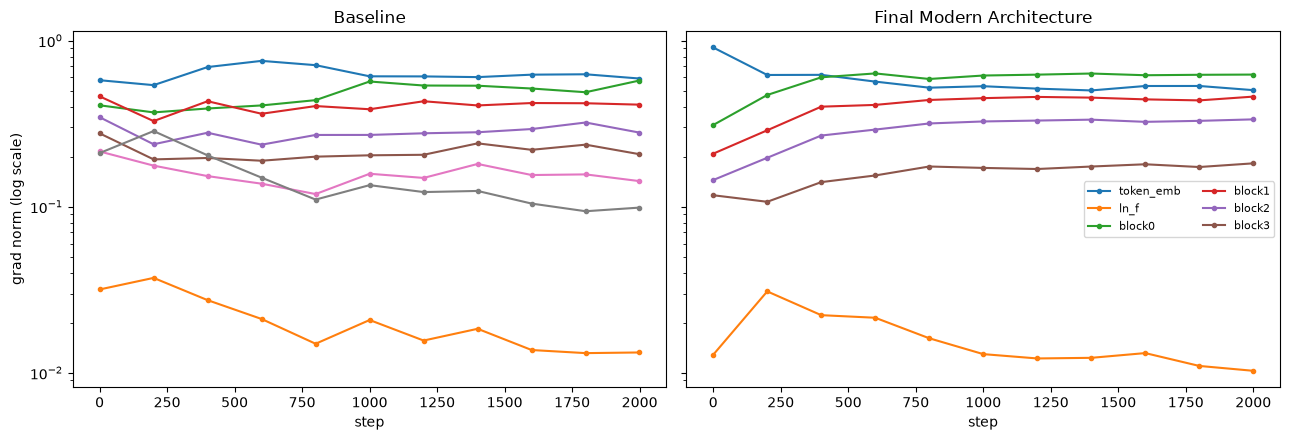

In [55]:
def plot_group_norms(history, ax, title):
    steps = [s for s, _ in history["group_norms"]]
    labels = list(history["group_norms"][0][1].keys())
    for label in labels:
        values = [norms[label] for _, norms in history["group_norms"]]
        ax.plot(steps, values, marker='.', label=label)
    ax.set_yscale("log")
    ax.set_xlabel("step")
    ax.set_title(title)


fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
plot_group_norms(history, axes[0], "Baseline")
plot_group_norms(history_full, axes[1], "Final Modern Architecture")
axes[0].set_ylabel("grad norm (log scale)")
axes[1].legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.savefig("contrast.pdf", bbox_inches="tight")
plt.show()

## 6.3 Sample Quality: Baseline vs. Final Architecture

The loss numbers say the final architecture is better. This checks whether the
difference is visible in the generated text. Identical prompt, identical
decoding settings, identical sampling seed, and only the trained weights differ.


In [56]:
def show_samples(model, cfg, label, prompt="ROMEO:", n_tokens=250, seed=42):
    np.random.seed(seed)
    print(f"{'=' * 70}\n{label}\n{'=' * 70}")
    print(generate(model, cfg, tokenizer, prompt=prompt,
                   max_new_tokens=n_tokens, temperature=0.8, top_k=20))
    print()


load_checkpoint(model, checkpoints[max(checkpoints)])
show_samples(model, config, "BASELINE (val loss 1.9125)")

load_checkpoint(model_full, checkpoints_full[max(checkpoints_full)])
show_samples(model_full, config_full, "FINAL MODERN ARCHITECTURE (val loss 1.5961)")

BASELINE (val loss 1.9125)
ROMEO:
Why carrocts cance reigno; new as that be
think dukesir dand the comse apple in sight.
For This if I her him father;
This a is I in horls, whe day I that;
So she may cand lesen we but stime to heavein by I
Take of dentoge in with on dom servil untur

FINAL MODERN ARCHITECTURE (val loss 1.5961)
ROMEO:
Which the world not be much am astic the business?
Till a heaven'd away
To save sight, what not lad so the daughter.
I would to
not home, worthy of it besign the law day:
Most it have reports: he would that I must cloud.

First Murderer:
By what you



## 6.4 Hyperparameter Study on the Final Architecture

Each configuration varies exactly one hyperparameter from the final
architecture, keeping everything else (seed, data order, step count, schedule)
identical. The reference point is the full modern run from Phase 5.

The sweep is designed to survive interruption: every completed run is written
to disk immediately, and re-running this cell skips runs whose results already
exist. Runs are ordered by ascending cost, so an early stop still yields the
cheaper configurations.

In [57]:
import pickle
from datetime import datetime

HP_DIR = "hp_runs"
os.makedirs(HP_DIR, exist_ok=True)

# (name, overrides) -- ordered by ascending expected runtime
HP_SWEEP = [
    ("ctx64",     dict(context_length=64)),
    ("layers2",   dict(n_layers=2)),
    ("lr1e-4",    dict(learning_rate=1e-4)),
    ("lr1e-3",    dict(learning_rate=1e-3)),
    ("heads2",    dict(n_heads=2)),
    ("heads8",    dict(n_heads=8)),
    ("layers6",   dict(n_layers=6)),
    ("ctx256",    dict(context_length=256)),
]


def hp_path(name):
    return os.path.join(HP_DIR, f"{name}.pkl")


def run_hp_sweep(sweep, base_config):
    """Train one variant per entry, persisting each result before moving on."""
    results = {}
    for name, overrides in sweep:
        path = hp_path(name)

        if os.path.exists(path):
            with open(path, "rb") as f:
                results[name] = pickle.load(f)
            print(f"[skip] {name}: loaded existing result "
                  f"(final val {results[name]['history']['val_loss'][-1]:.4f})")
            continue

        cfg = dataclasses.replace(base_config, **overrides)
        start = time.time()
        print(f"\n{'=' * 70}")
        print(f"[start] {name}  {overrides}   {datetime.now():%Y-%m-%d %H:%M:%S}")
        print(f"{'=' * 70}", flush=True)

        set_seed(SEED)
        m = GPTModel(cfg)
        hist, _ = train(m, cfg, log_interval=500, eval_interval=250)  # checkpoints discarded

        elapsed = time.time() - start
        record = {
            "name": name,
            "overrides": overrides,
            "history": hist,
            "n_params": count_params(m),
            "elapsed_sec": elapsed,
        }
        with open(path, "wb") as f:
            pickle.dump(record, f)
        results[name] = record

        print(f"[done] {name}: val {hist['val_loss'][-1]:.4f} | "
              f"{elapsed / 60:.1f} min | saved to {path}", flush=True)

    return results


hp_results = run_hp_sweep(HP_SWEEP, config_full)
print(f"\n\nSweep finished: {len(hp_results)}/{len(HP_SWEEP)} runs available.")

[skip] ctx64: loaded existing result (final val 1.6666)
[skip] layers2: loaded existing result (final val 1.7172)
[skip] lr1e-4: loaded existing result (final val 1.8984)
[skip] lr1e-3: loaded existing result (final val 1.5266)
[skip] heads2: loaded existing result (final val 1.6170)
[skip] heads8: loaded existing result (final val 1.6339)
[skip] layers6: loaded existing result (final val 1.5602)
[skip] ctx256: loaded existing result (final val 1.6019)


Sweep finished: 8/8 runs available.


config              val    train     gap      params     min
reference        1.5961   1.4403  0.1559   1,058,048       -
ctx64            1.6666   1.5379  0.1287   1,058,048      40
layers2          1.7172   1.5824  0.1347     533,248      40
lr1e-4           1.8984   1.8133  0.0851   1,058,048      79
lr1e-3           1.5266   1.2670  0.2596   1,058,048      78
heads2           1.6170   1.4217  0.1953   1,058,048      70
heads8           1.6339   1.4469  0.1870   1,058,048      91
layers6          1.5602   1.3988  0.1614   1,582,848     116
ctx256           1.6019   1.3777  0.2242   1,058,048     201


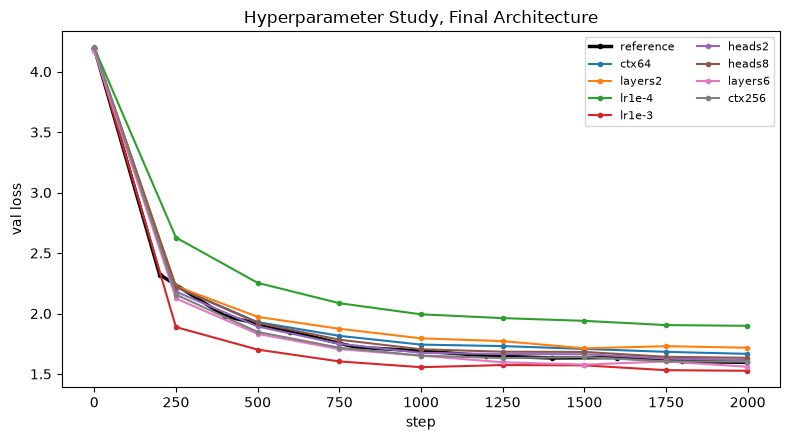

In [58]:
# Reference: the final architecture from Phase 5 (already trained)
ref = {"name": "reference", "overrides": {}, "history": history_full,
       "n_params": count_params(model_full), "elapsed_sec": None}

rows = [ref] + [hp_results[name] for name, _ in HP_SWEEP if name in hp_results]

print(f"{'config':14s} {'val':>8s} {'train':>8s} {'gap':>7s} {'params':>11s} {'min':>7s}")
for r in rows:
    h = r["history"]
    tr, va = h["train_loss"][-1], h["val_loss"][-1]
    mins = f"{r['elapsed_sec'] / 60:.0f}" if r["elapsed_sec"] else "-"
    print(f"{r['name']:14s} {va:>8.4f} {tr:>8.4f} {va - tr:>7.4f} "
          f"{r['n_params']:>11,d} {mins:>7s}")

plt.figure(figsize=(8, 4.5))
for r in rows:
    h = r["history"]
    style = dict(lw=2.5, color="black") if r["name"] == "reference" else {}
    plt.plot(h["val_step"], h["val_loss"], marker='.', label=r["name"], **style)
plt.xlabel("step"); plt.ylabel("val loss")
plt.title("Hyperparameter Study, Final Architecture")
plt.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

## 6.5 Interpretation

Two configurations beat the reference on validation loss, `lr1e-3` and
`layers6`, and both trade away its balance to do so: `lr1e-3` pays for the
lowest validation loss in the sweep with the largest overfitting gap, and
`layers6` needs 50% more parameters and roughly three times the wall-clock
time. Learning rate shows the widest spread of any hyperparameter tested;
`lr1e-4` underfits within the fixed step budget. Context length cuts both
ways, with `ctx64` losing information per prediction and `ctx256` not
converting its longer training time into better generalization. Depth and
head count move validation loss by less than 0.03 in either direction.
The reference configuration was not the best on any single axis, and it was
not meant to be. It is the balance point the sweep was measured against.

# Summary

Starting from a GPT-2-style baseline with a fully hand-derived backward pass,
four modern components were introduced one at a time: RMSNorm, SwiGLU, RoPE,
and weight tying. Every component passed an isolated numerical gradient check
before training, and the full architecture passed an end-to-end check.

Validation loss fell from 1.9125 to 1.5961 across the four steps, and the
number of steps needed to reach a validation loss below 2.0 fell from 1200 to
400. RoPE and weight tying improved both losses while removing parameters;
SwiGLU bought its improvement with capacity and shows the largest overfitting
gap of the four. Generation quality tracks the loss numbers: the baseline
produces mostly non-words, the final model produces mostly real English with
correct speaker-label formatting.